# 11 Benchmark dashboard and metric audit

Read-only evaluation of saved LOSO out-of-fold predictions. **No training, feature selection, SHAP computation or automatic winner declaration.** Metrics are recomputed from labels and probabilities, not copied uncritically from summaries. Different tasks, availability designs and sensor-missing scenarios are kept separate.

Primary endpoint: equal-participant mean balanced accuracy for baseline/stress/amusement on the common valid windows. Reduced variants, advanced algorithms and fusion extensions remain exploratory. Selecting the maximum of many observed results introduces optimism: this notebook is a comparative report, not independent validation of a winner.

In [1]:
from pathlib import Path
import os,json,hashlib,itertools,warnings
from io import BytesIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score,balanced_accuracy_score,f1_score,
    precision_score,recall_score,roc_auc_score,average_precision_score,confusion_matrix)
from IPython.display import display,Markdown,Image

PROJECT_ROOT=None
ARTIFACTS_REL='artifacts/revision_v2'
here=Path.cwd().resolve()
ROOT=Path(PROJECT_ROOT).resolve() if PROJECT_ROOT else next(
    (p for p in [here,*here.parents] if (p/'configs/config.yaml').is_file()),None)
if ROOT is None:raise RuntimeError('Place this notebook inside the project or set PROJECT_ROOT.')
A=ROOT/ARTIFACTS_REL
OUT=A/'benchmark';FIG=OUT/'figures';FIG.mkdir(parents=True,exist_ok=True)
SHOW_FIGURES=True;N_BOOTSTRAP=10000;SEED=42;TOP_DISPLAY=15
CLASS_NAMES={0:'Non-stress',1:'Baseline',2:'Stress',3:'Amusement',4:'Meditation'}
SITES={'chest':'Chest','wrist':'Wrist','early_fusion':'Early fusion','late_fusion':'Late fusion','modality_dropout':'Modality dropout'}
MODELS={'logistic_regression':'Logistic regression','random_forest':'Random forest','xgboost':'XGBoost','lightgbm':'LightGBM','mlp':'MLP','majority':'Majority'}
sns.set_theme(style='whitegrid')
def show(fig,name):
    fig.savefig(FIG/name,dpi=300,bbox_inches='tight')
    if SHOW_FIGURES:
        with BytesIO() as b:
            fig.savefig(b,format='png',dpi=90,bbox_inches='tight');png=b.getvalue()
        display(Image(data=png))
    plt.close(fig)
def safe(s):return ''.join(x if x.isalnum() or x in '._-' else '_' for x in str(s))
def ci(values):
    values=np.asarray(values,float)
    values=values[np.isfinite(values)]
    if len(values)<2:return np.nan,np.nan
    rng=np.random.default_rng(SEED)
    means=values[rng.integers(0,len(values),size=(N_BOOTSTRAP,len(values)))].mean(1)
    return tuple(np.quantile(means,[.025,.975]))
def signature(frame):
    keys=frame[['subject_id','window_id','label']].sort_values(['subject_id','window_id']).reset_index(drop=True)
    return hashlib.sha256(keys.to_csv(index=False).encode()).hexdigest()
def readable(site,model,variant):
    return f"{SITES.get(site,site)} · {MODELS.get(model,model)} · {variant.replace('reduced_','r≤')}"
expected_subjects=None
lock=A/'protocol_lock.json'
if lock.is_file():
    expected_subjects=set(json.loads(lock.read_text(encoding='utf-8'))['config']['dataset']['expected_subjects'])
print('Benchmark configured: saved predictions only, no model fitting.')


Benchmark configured: saved predictions only, no model fitting.


## Discover experiments and recompute metrics

Checks: unique participant/window identifiers; finite, normalized class probabilities; valid class order; all required classes per test participant; expected participant coverage; agreement with saved fold metrics. A fingerprint of the exact participant/window/label set defines comparable samples. Models sharing a task but different sample sets are not silently pooled.

Full-model notebook09b reruns that exactly reproduce an existing experiment are recorded as duplicates, not counted as independent evidence. If their probabilities differ, they remain distinct runs and the difference is audited. Missing or invalid experiments are reported; a zero score is never substituted for absent data.

In [2]:
experiments={};fold_rows=[];class_rows=[];audit=[];aliases=[]

def register(key,task,site,model,variant,role,pred,classes,saved_folds=None,feature_counts=None):
    classes=list(map(int,classes));pred=pred.copy()
    if pred.empty:raise ValueError('No OOF rows')
    if pred.duplicated(['subject_id','window_id']).any():raise ValueError('Duplicate OOF rows')
    if not pred.label.isin(classes).all():raise ValueError('Unexpected class labels')
    p=pred[[f'p_{k}' for k in classes]].to_numpy(float)
    if not np.isfinite(p).all() or (p<0).any() or (p>1).any() or not np.allclose(p.sum(1),1,atol=1e-6):raise ValueError('Invalid probabilities')
    predicted=np.asarray(classes)[p.argmax(1)];pred['recomputed_prediction']=predicted
    if 'prediction' in pred and not pred.prediction.eq(pred.recomputed_prediction).all():raise ValueError('Stored predicted labels differ')
    fp=signature(pred)
    if expected_subjects is not None and set(pred.subject_id)!=expected_subjects:
        raise ValueError('Participant coverage differs from expected original cohort')
    for old_key,old in experiments.items():
        if (task,site,model,variant,fp)==(old['task'],old['site'],old['model'],old['variant'],old['signature']):
            a=pred.sort_values(['subject_id','window_id'])
            b=old['predictions'].sort_values(['subject_id','window_id'])
            if np.allclose(a[[f'p_{k}' for k in classes]],b[[f'p_{k}' for k in classes]],rtol=1e-7,atol=1e-8):
                aliases.append(dict(alias=key,retained=old_key,reason='identical OOF probabilities and samples'))
                return
            audit.append(dict(experiment=key,status='distinct_rerun',detail='same design, different OOF probabilities'))
    saved={int(row['subject_id']):row for row in (saved_folds or [])}
    local=[];localclass=[];metric_mismatches=[]
    for sid,g in pred.groupby('subject_id'):
        if set(g.label)!=set(classes):raise ValueError(f'Test participant S{int(sid)} lacks a required class')
        y=g.label.to_numpy();guess=g.recomputed_prediction.to_numpy();probs=g[[f'p_{k}' for k in classes]].to_numpy(float)
        ba=balanced_accuracy_score(y,guess);f1=f1_score(y,guess,labels=classes,average='macro',zero_division=0)
        item=dict(experiment=key,task=task,site=site,model=model,variant=variant,role=role,subject_id=int(sid),
            n_windows=len(g),balanced_accuracy=ba,macro_f1=f1,accuracy=accuracy_score(y,guess),
            precision_macro=precision_score(y,guess,labels=classes,average='macro',zero_division=0),
            recall_macro=recall_score(y,guess,labels=classes,average='macro',zero_division=0),
            macro_roc_auc=float(np.mean([roc_auc_score(y==k,probs[:,j]) for j,k in enumerate(classes)])),
            macro_AP=float(np.mean([average_precision_score(y==k,probs[:,j]) for j,k in enumerate(classes)])),
            n_features=(feature_counts or {}).get(int(sid),np.nan))
        for field,candidates in [('balanced_accuracy',['balanced_accuracy']),('macro_f1',['macro_f1','f1_macro'])]:
            for stored_name in candidates:
                if sid in saved and stored_name in saved[sid]:
                    if not np.isclose(item[field],saved[sid][stored_name],atol=1e-9):metric_mismatches.append(f'S{sid}:{field}')
                    break
        local.append(item)
        for j,k in enumerate(classes):
            name=({0:'Non-stress',1:'Stress'}.get(k,str(k)) if task=='stress_vs_nonstress' else CLASS_NAMES.get(k,str(k)))
            localclass.append(dict(experiment=key,subject_id=int(sid),class_label=k,class_name=name,
                recall=float(np.mean(guess[y==k]==k)),n_windows=int((y==k).sum())))
    if metric_mismatches:raise ValueError('Saved fold metrics mismatch: '+', '.join(metric_mismatches))
    experiments[key]=dict(task=task,site=site,model=model,variant=variant,role=role,signature=fp,
        predictions=pred,classes=classes,label=readable(site,model,variant))
    fold_rows.extend(local);class_rows.extend(localclass)
    audit.append(dict(experiment=key,status='validated',detail='OOF checks and metric recomputation passed'))

for results in [A/'results',A/'exploratory/results',A/'exploratory/four_class/results']:
    for path in sorted(results.glob('*.json')):
        obj=json.loads(path.read_text(encoding='utf-8'))
        if not isinstance(obj,dict) or not all(k in obj for k in ['task','site','model','classes','folds']):continue
        key=path.stem;pred_path=path.with_name(key+'_predictions.csv')
        if not pred_path.is_file():audit.append(dict(experiment=key,status='missing',detail='OOF predictions absent'));continue
        task=obj['task']
        if task=='three_class_both_present':task='three_class'
        role='primary' if key.startswith('confirmatory_') else 'secondary' if key.startswith('secondary_') else 'exploratory'
        counts={}
        if obj.get('method') is None:
            folder=results.parent/'models'/f"{obj['task']}_{obj['site']}_{obj['model']}"
            for m in folder.glob('S*_metadata.json'):
                meta=json.loads(m.read_text(encoding='utf-8'));counts[int(meta['test_subject'])]=len(meta['features'])
        try:register(key,task,obj['site'],obj['model'],'full',role,pd.read_csv(pred_path),obj['classes'],obj['folds'],counts)
        except (ValueError,KeyError) as exc:audit.append(dict(experiment=key,status='invalid',detail=str(exc)))

# Use one sensitivity run; never combine two training runs under one name.
SENSITIVITY_ROOT=A/'exploratory/feature_redundancy_saved_models'
if not (SENSITIVITY_ROOT/'predictions.csv').is_file():SENSITIVITY_ROOT=A/'exploratory/feature_redundancy_importance'
if (SENSITIVITY_ROOT/'predictions.csv').is_file():
    sensitivity=pd.read_csv(SENSITIVITY_ROOT/'predictions.csv')
    saved=pd.read_csv(SENSITIVITY_ROOT/'fold_metrics.csv')
    for (site,model,variant),p in sensitivity.groupby(['site','model','variant']):
        metrics=saved[(saved.site==site)&(saved.model==model)&(saved.variant==variant)]
        key=f'sensitivity_{site}_{model}_{variant}'
        try:register(key,'three_class',site,model,variant,'post_hoc_sensitivity',p,[1,2,3],metrics.to_dict('records'),dict(zip(metrics.subject_id,metrics.n_features)))
        except (ValueError,KeyError) as exc:audit.append(dict(experiment=key,status='invalid',detail=str(exc)))
else:audit.append(dict(experiment='sensitivity',status='missing',detail='No sensitivity OOF table'))
fold_metrics=pd.DataFrame(fold_rows);class_metrics=pd.DataFrame(class_rows)
if fold_metrics.empty:raise RuntimeError('No valid experiments: inspect audit.')
audit=pd.DataFrame(audit);display(audit)
audit.to_csv(OUT/'metric_audit.csv',index=False)
pd.DataFrame(aliases).to_csv(OUT/'duplicate_run_aliases.csv',index=False)
fold_metrics.to_csv(OUT/'recomputed_fold_metrics.csv',index=False)
class_metrics.to_csv(OUT/'per_class_recalls.csv',index=False)


,experiment,status,detail
0,confirmatory_chest_logistic_regression,validated,OOF checks and metric recomputation passed
1,confirmatory_chest_majority,validated,OOF checks and metric recomputation passed
2,confirmatory_chest_random_forest,validated,OOF checks and metric recomputation passed
3,confirmatory_early_fusion_logistic_regression,validated,OOF checks and metric recomputation passed
4,confirmatory_early_fusion_majority,validated,OOF checks and metric recomputation passed
...,...,...,...
79,sensitivity_wrist_random_forest_reduced_0.90,validated,OOF checks and metric recomputation passed
80,sensitivity_wrist_random_forest_reduced_0.95,validated,OOF checks and metric recomputation passed
81,sensitivity_wrist_xgboost_reduced_0.80,validated,OOF checks and metric recomputation passed
82,sensitivity_wrist_xgboost_reduced_0.90,validated,OOF checks and metric recomputation passed


## Leaderboards: same task and exactly matching samples

The sample-set fingerprint separates independent-availability analyses and incompatible window sets. Tables are ordered by mean balanced accuracy for navigation, not a statistical winner selection. Subject-bootstrap intervals are conditional on fitted predictions and not simultaneous intervals. Fold SD describes participant variability and is not a confidence interval.

### availability_three_class__samples_1

label,role,n_subjects,n_windows,BA_mean,BA_low,BA_high,F1_macro,AUC_macro,mean_n_features
Chest · Logistic regression · full,secondary,15,1040,0.650,0.583,0.723,0.597,0.902,26.000


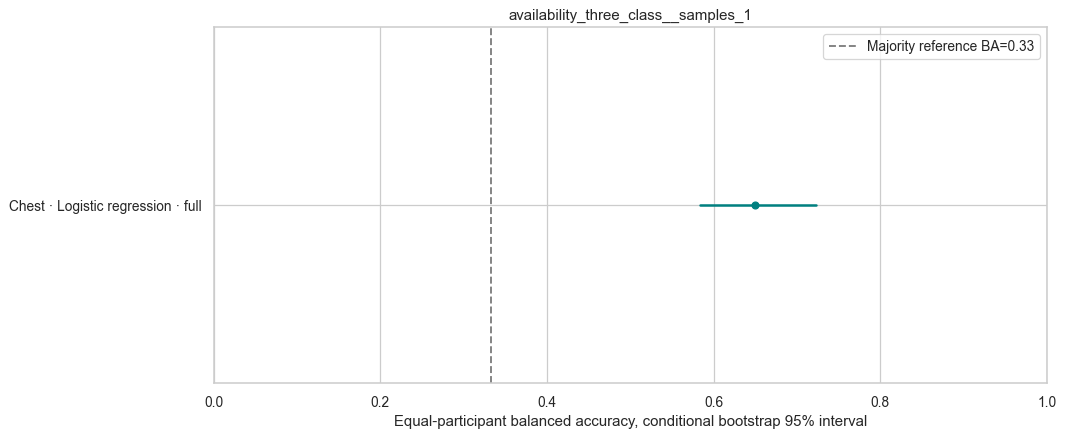

### availability_three_class__samples_2

label,role,n_subjects,n_windows,BA_mean,BA_low,BA_high,F1_macro,AUC_macro,mean_n_features
Wrist · Logistic regression · full,secondary,15,1007,0.660,0.577,0.741,0.632,0.870,19.000


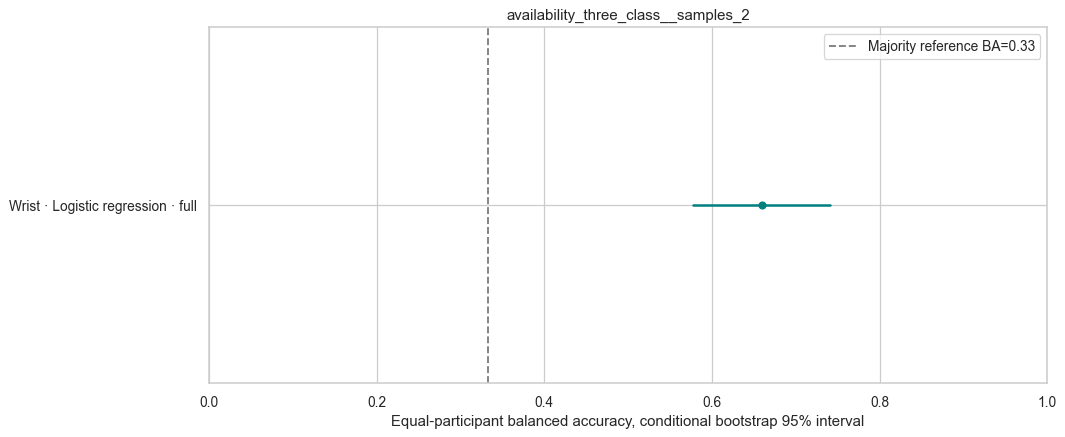

### baseline_vs_stress__samples_1

label,role,n_subjects,n_windows,BA_mean,BA_low,BA_high,F1_macro,AUC_macro,mean_n_features
Wrist · Logistic regression · full,secondary,15,845,0.912,0.854,0.957,0.904,0.977,19.000
Early fusion · Logistic regression · full,secondary,15,845,0.881,0.805,0.945,0.866,0.990,45.000
Chest · Logistic regression · full,secondary,15,845,0.826,0.733,0.916,0.808,0.944,26.000


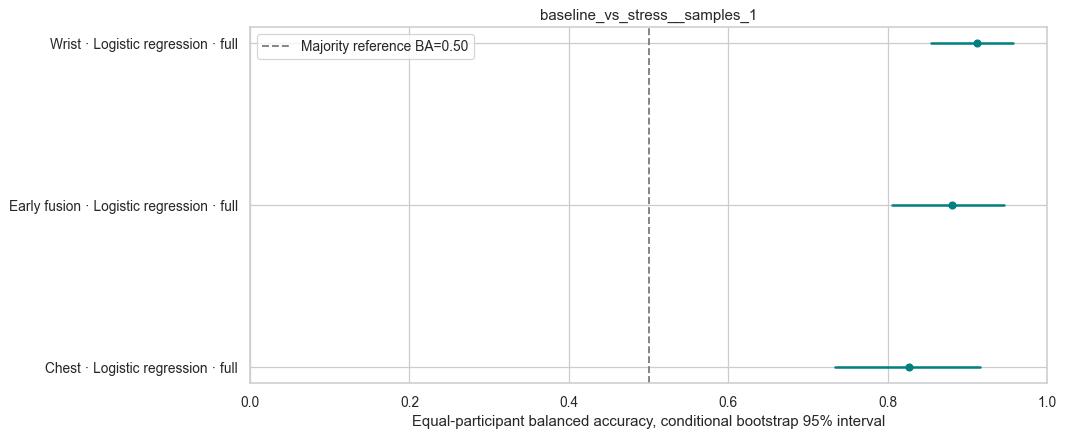

### four_class__samples_1

label,role,n_subjects,n_windows,BA_mean,BA_low,BA_high,F1_macro,AUC_macro,mean_n_features
Early fusion · Random forest · full,exploratory,15,1338,0.719,0.661,0.778,0.702,0.930,45.000
Chest · Random forest · full,exploratory,15,1338,0.688,0.629,0.745,0.663,0.922,26.000
Early fusion · Logistic regression · full,exploratory,15,1338,0.686,0.597,0.772,0.651,0.916,45.000
Chest · Logistic regression · full,exploratory,15,1338,0.676,0.596,0.757,0.620,0.920,26.000
Wrist · Random forest · full,exploratory,15,1338,0.590,0.552,0.626,0.560,0.836,19.000
Wrist · Logistic regression · full,exploratory,15,1338,0.544,0.499,0.589,0.512,0.830,19.000
Chest · Majority · full,exploratory,15,1338,0.250,0.250,0.250,0.146,0.500,26.000
Early fusion · Majority · full,exploratory,15,1338,0.250,0.250,0.250,0.146,0.500,45.000
Wrist · Majority · full,exploratory,15,1338,0.250,0.250,0.250,0.146,0.500,19.000


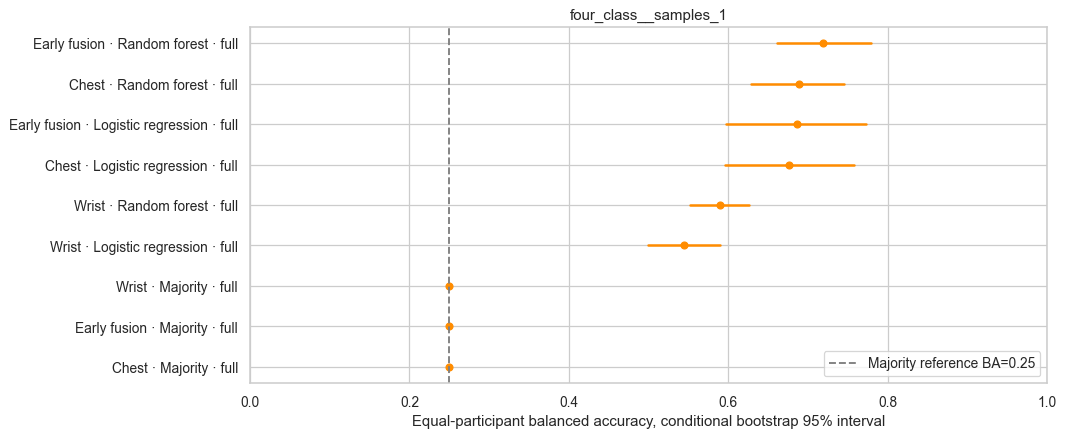

### stress_vs_nonstress__samples_1

label,role,n_subjects,n_windows,BA_mean,BA_low,BA_high,F1_macro,AUC_macro,mean_n_features
Wrist · Logistic regression · full,secondary,15,1005,0.903,0.851,0.950,0.889,0.975,19.000
Early fusion · Logistic regression · full,secondary,15,1005,0.831,0.757,0.900,0.804,0.978,45.000
Chest · Logistic regression · full,secondary,15,1005,0.822,0.740,0.900,0.792,0.940,26.000


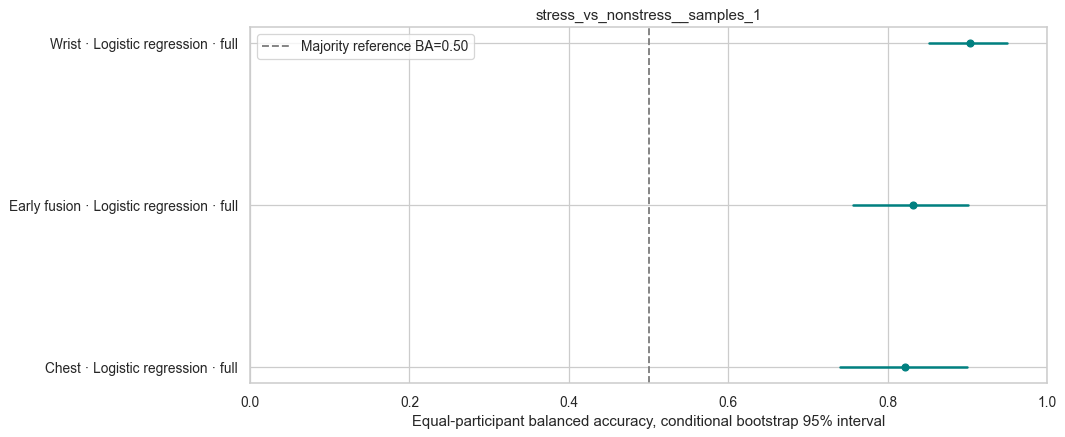

### three_class__samples_1

label,role,n_subjects,n_windows,BA_mean,BA_low,BA_high,F1_macro,AUC_macro,mean_n_features
Late fusion · Logistic regression · full,exploratory,15,1005,0.733,0.660,0.803,0.700,0.908,N/A
Early fusion · Random forest · r≤0.90,post_hoc_sensitivity,15,1005,0.724,0.661,0.785,0.704,0.915,35.067
Modality dropout · Logistic regression · full,exploratory,15,1005,0.714,0.637,0.786,0.677,0.926,N/A
Wrist · XGBoost · r≤0.95,post_hoc_sensitivity,15,1005,0.707,0.644,0.772,0.689,0.870,17.933
Early fusion · Random forest · r≤0.95,post_hoc_sensitivity,15,1005,0.703,0.646,0.757,0.684,0.908,38.867
Early fusion · Random forest · r≤0.80,post_hoc_sensitivity,15,1005,0.699,0.640,0.757,0.679,0.906,32.133
Chest · LightGBM · full,exploratory,15,1005,0.697,0.614,0.780,0.662,0.880,26.000
Early fusion · Logistic regression · r≤0.95,post_hoc_sensitivity,15,1005,0.690,0.599,0.775,0.645,0.911,38.867
Wrist · MLP · r≤0.95,post_hoc_sensitivity,15,1005,0.690,0.607,0.772,0.671,0.867,17.933
Wrist · XGBoost · full,exploratory,15,1005,0.689,0.628,0.754,0.674,0.866,19.000


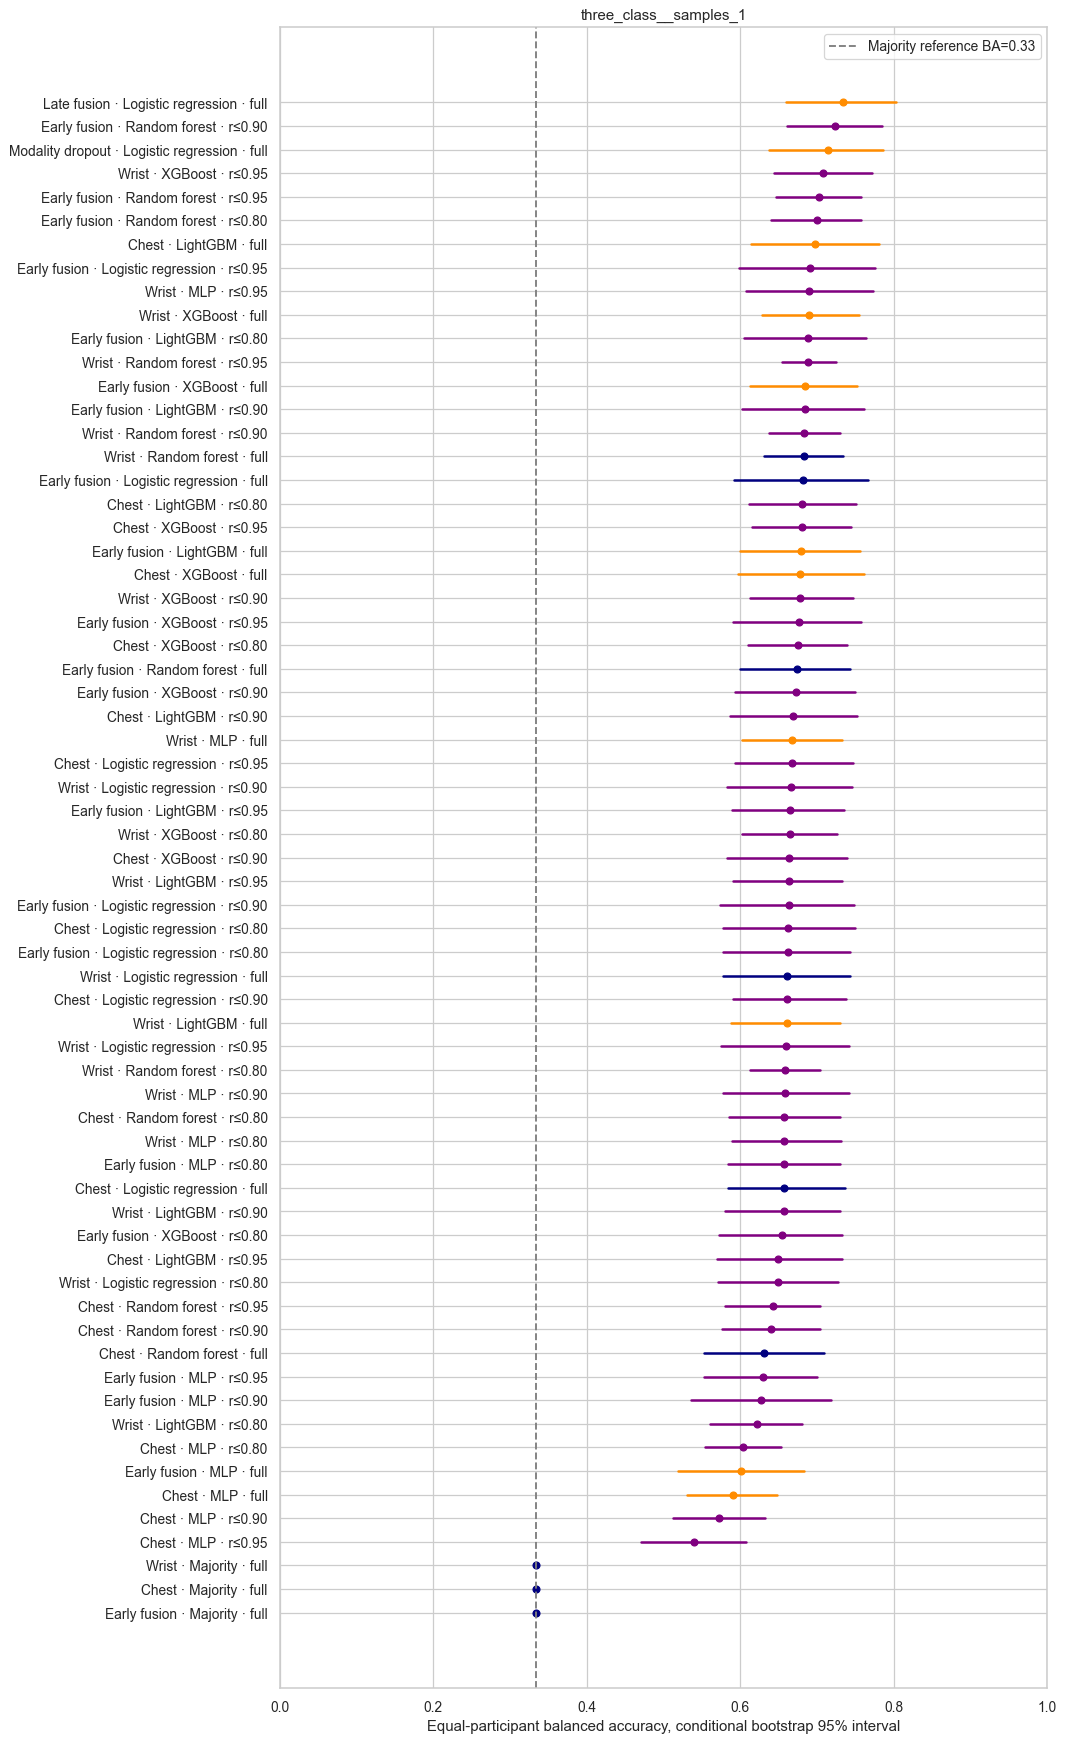

### three_class_chest_missing__samples_1

label,role,n_subjects,n_windows,BA_mean,BA_low,BA_high,F1_macro,AUC_macro,mean_n_features
Modality dropout · Logistic regression · full,exploratory,15,1005,0.646,0.569,0.720,0.620,0.859,N/A


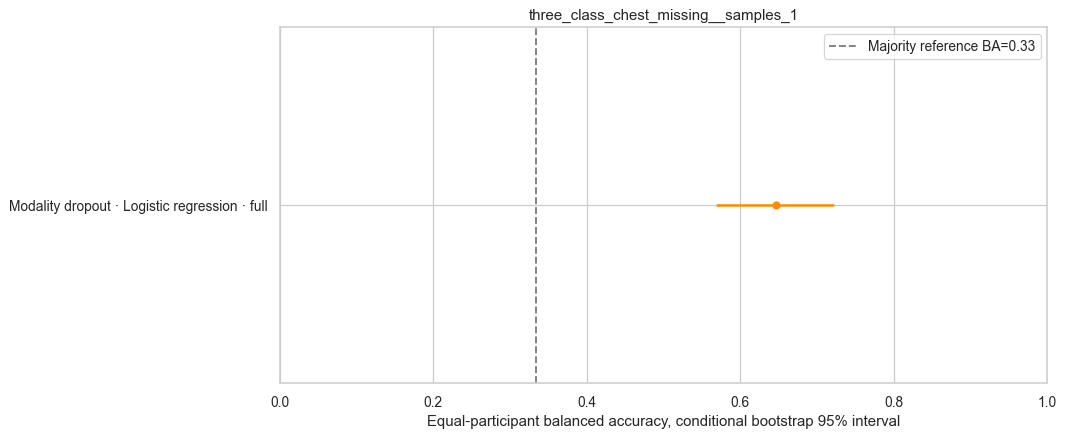

### three_class_wrist_missing__samples_1

label,role,n_subjects,n_windows,BA_mean,BA_low,BA_high,F1_macro,AUC_macro,mean_n_features
Modality dropout · Logistic regression · full,exploratory,15,1005,0.645,0.582,0.713,0.588,0.904,N/A


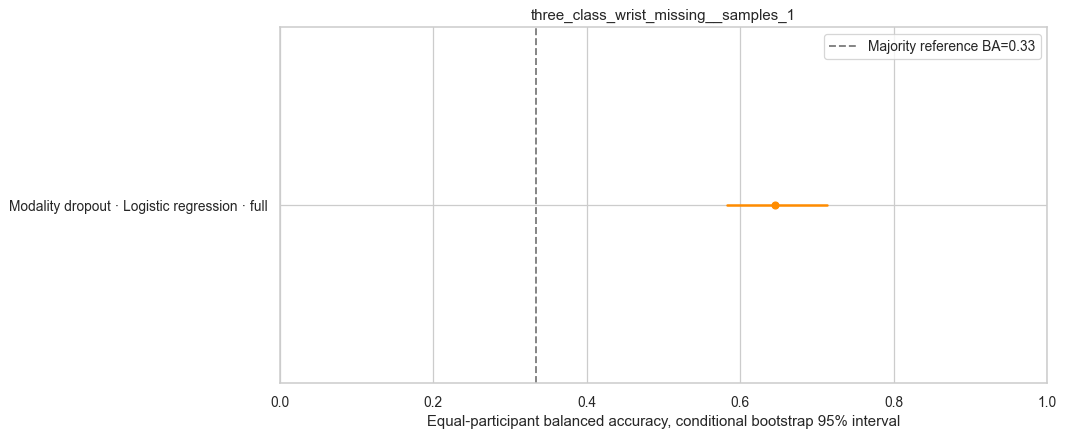

In [3]:
summaries=[]
for key,meta in experiments.items():
    g=fold_metrics[fold_metrics.experiment.eq(key)]
    low,high=ci(g.balanced_accuracy)
    summaries.append(dict(experiment=key,label=meta['label'],task=meta['task'],site=meta['site'],model=meta['model'],variant=meta['variant'],role=meta['role'],
        sample_signature=meta['signature'],n_subjects=len(g),n_windows=int(g.n_windows.sum()),
        BA_mean=g.balanced_accuracy.mean(),BA_sd=g.balanced_accuracy.std(),BA_low=low,BA_high=high,
        F1_macro=g.macro_f1.mean(),accuracy=g.accuracy.mean(),AUC_macro=g.macro_roc_auc.mean(),AP_macro=g.macro_AP.mean(),
        mean_n_features=g.n_features.mean(),min_subject_BA=g.balanced_accuracy.min()))
benchmark=pd.DataFrame(summaries)
benchmark['sample_group']=benchmark.groupby('task').sample_signature.transform(lambda s:pd.factorize(s,sort=True)[0]+1)
benchmark['benchmark_group']=benchmark.task+'__samples_'+benchmark.sample_group.astype(str)
benchmark=benchmark.sort_values(['benchmark_group','BA_mean'],ascending=[True,False])
benchmark.to_csv(OUT/'benchmark_summary.csv',index=False)
for group,g in benchmark.groupby('benchmark_group'):
    display(Markdown(f'### {group}'))
    display(g[['label','role','n_subjects','n_windows','BA_mean','BA_low','BA_high','F1_macro','AUC_macro','mean_n_features']].style.format(
        {col:'{:.3f}' for col in ['BA_mean','BA_low','BA_high','F1_macro','AUC_macro','mean_n_features']},na_rep='N/A').hide(axis='index'))
    g=g.sort_values('BA_mean')
    fig,ax=plt.subplots(figsize=(12,max(5,len(g)*.30)))
    y=np.arange(len(g));palette={'primary':'navy','secondary':'teal','exploratory':'darkorange','post_hoc_sensitivity':'purple'}
    for i,row in enumerate(g.itertuples()):
        ax.plot([row.BA_low,row.BA_high],[i,i],color=palette[row.role],linewidth=2)
        ax.scatter(row.BA_mean,i,color=palette[row.role],s=30)
    ax.set(yticks=y,yticklabels=g.label,xlim=(0,1),xlabel='Equal-participant balanced accuracy, conditional bootstrap 95% interval',title=group)
    chance=1/len(experiments[g.experiment.iloc[0]]['classes']);ax.axvline(chance,color='gray',linestyle='--',label=f'Majority reference BA={chance:.2f}')
    ax.legend();fig.tight_layout();show(fig,f'leaderboard_{safe(group)}.png')


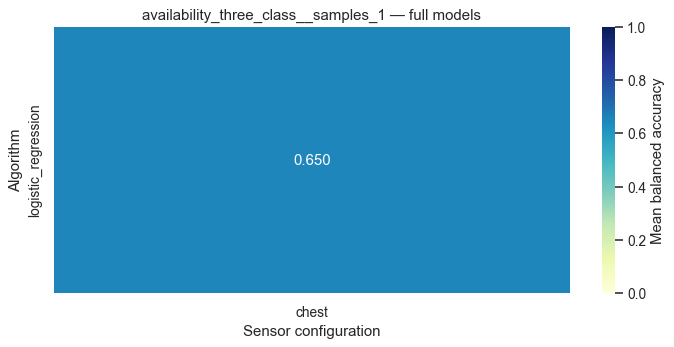

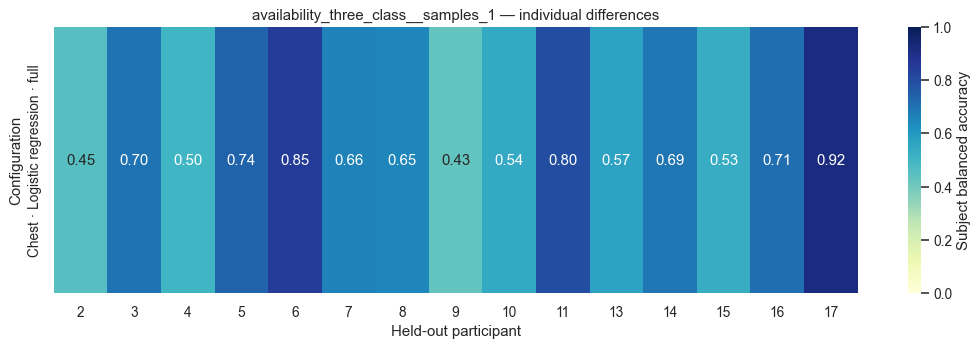

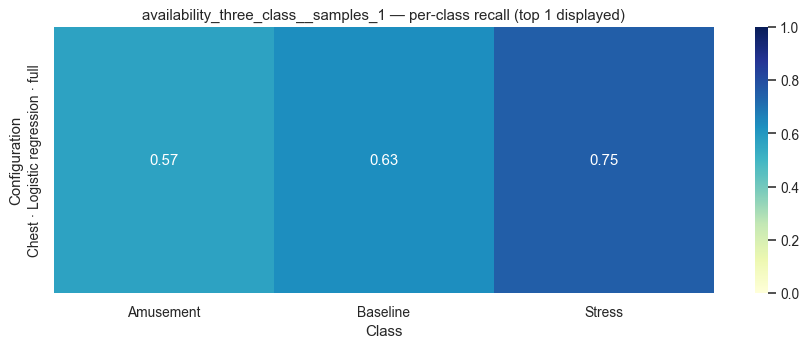

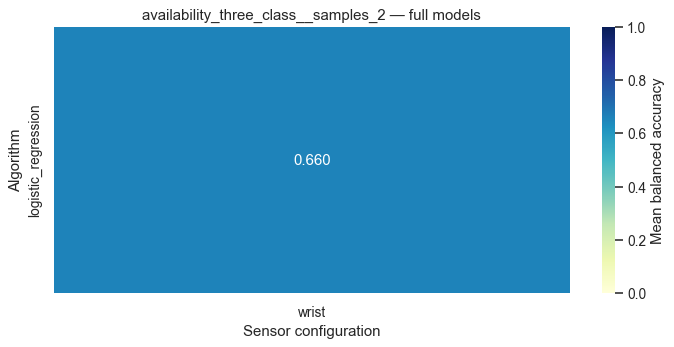

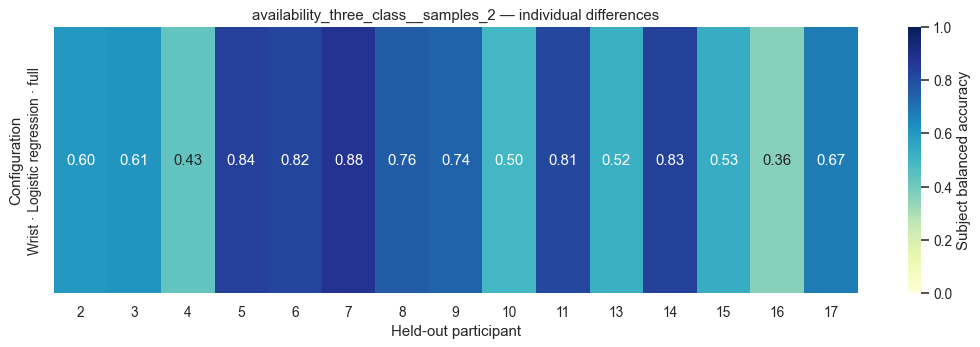

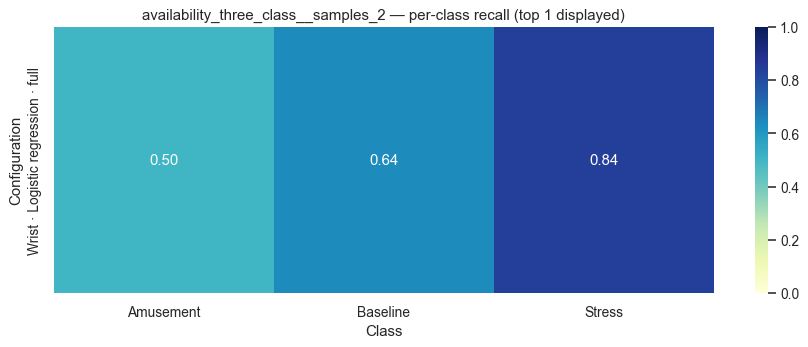

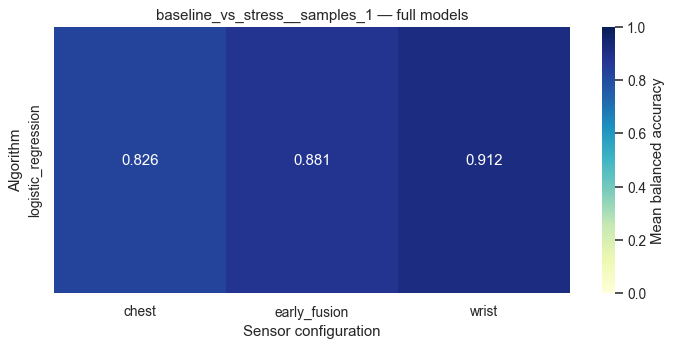

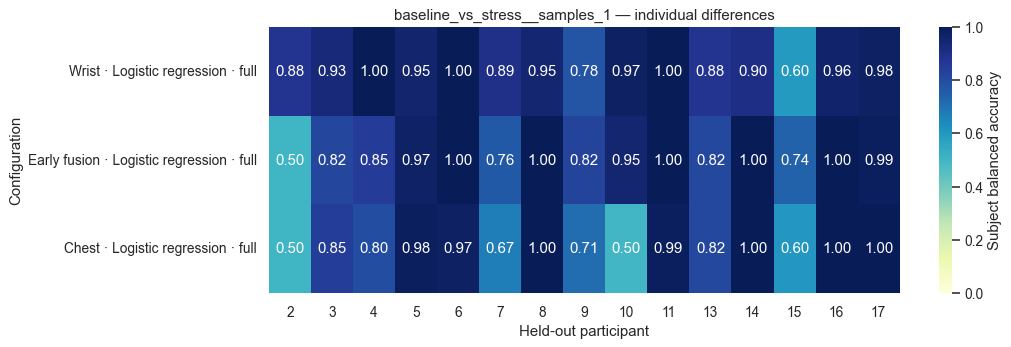

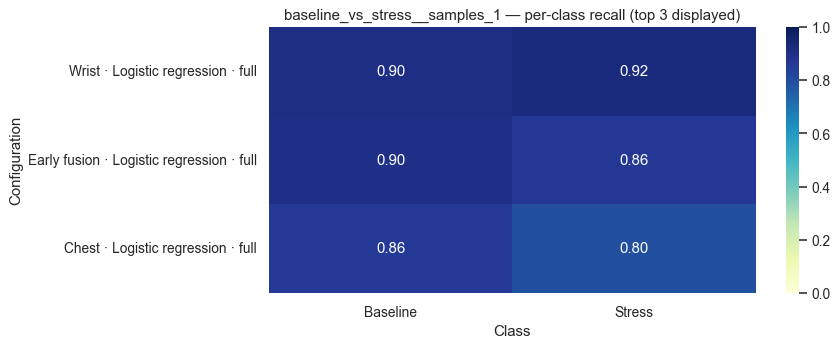

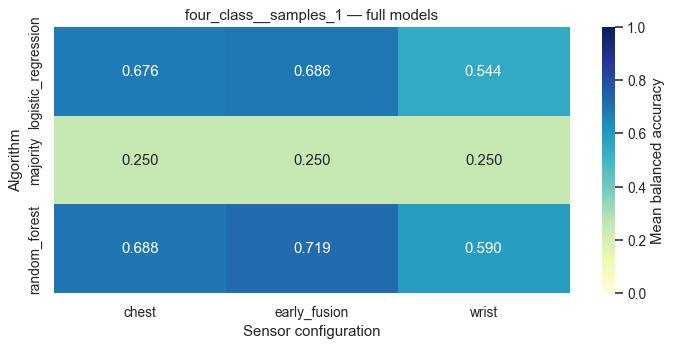

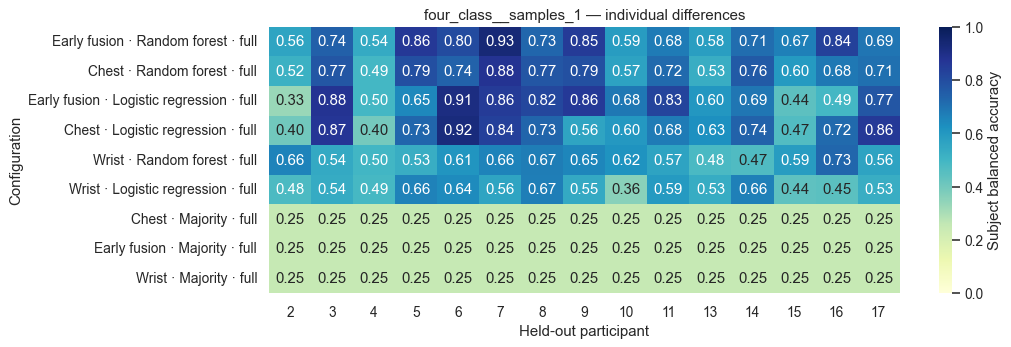

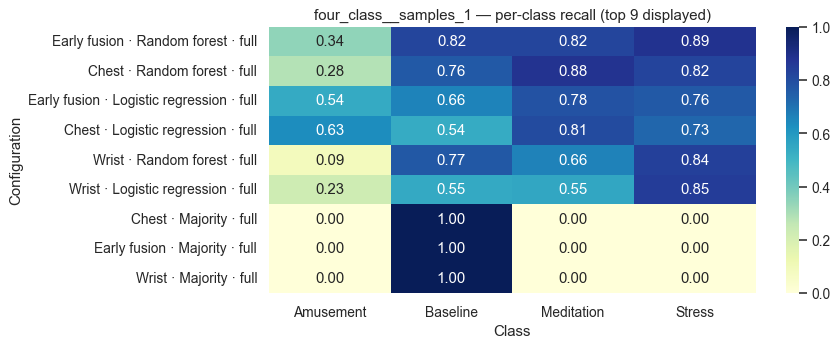

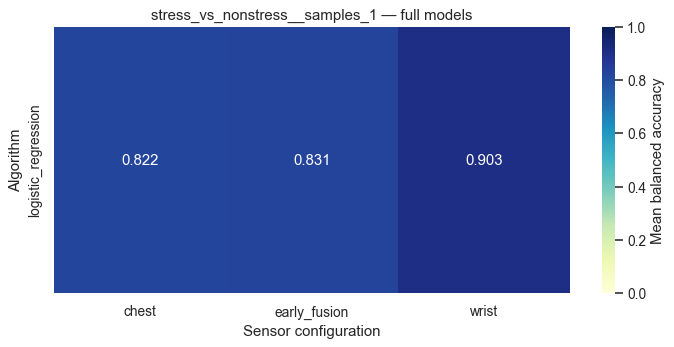

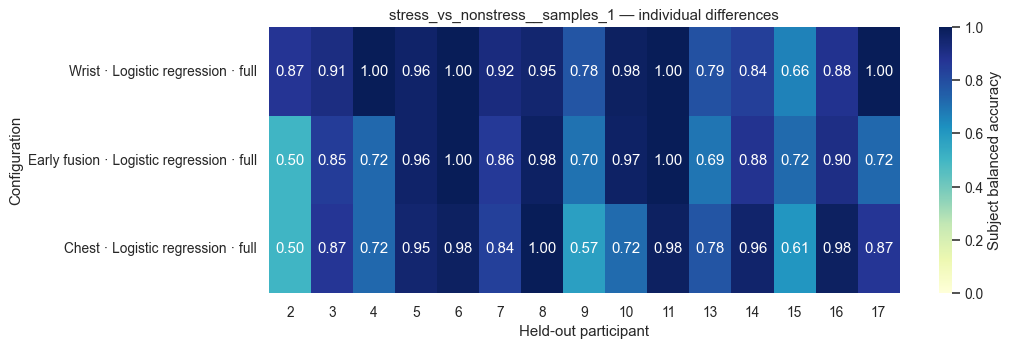

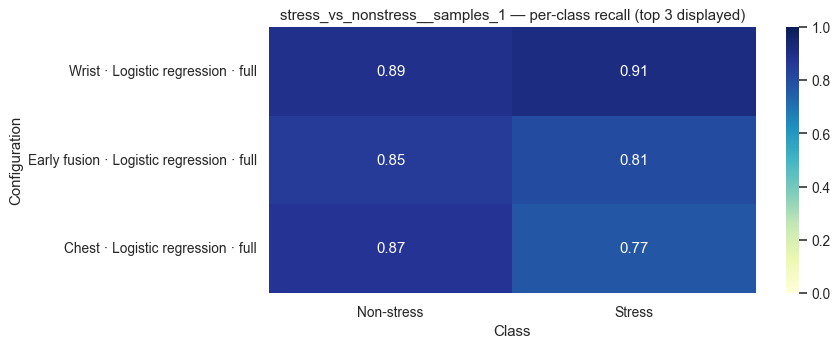

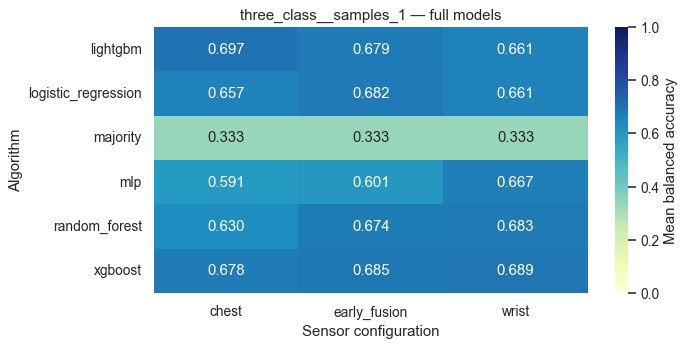

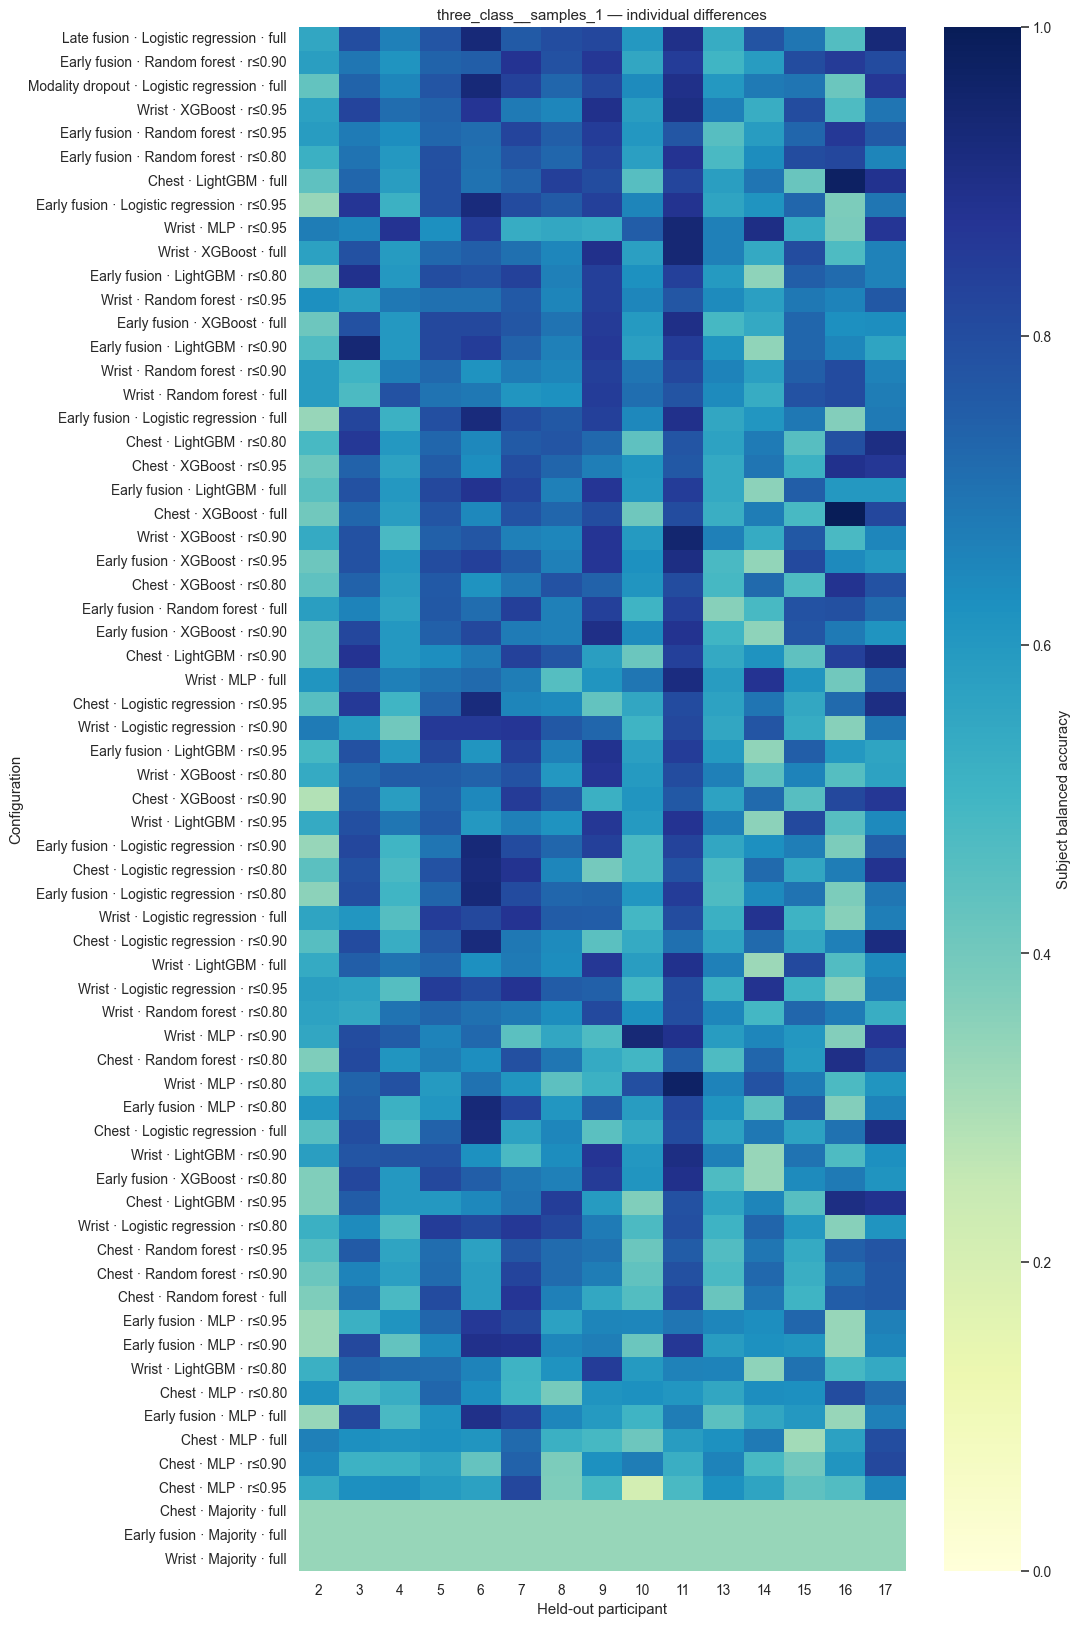

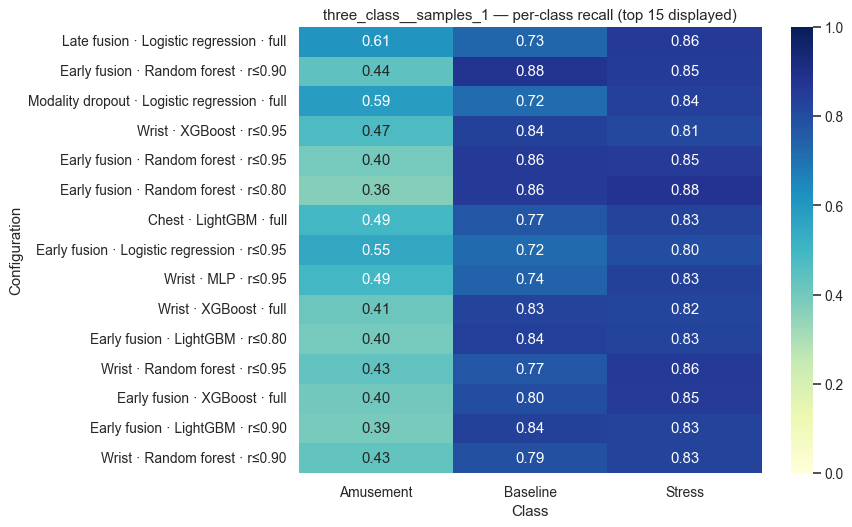

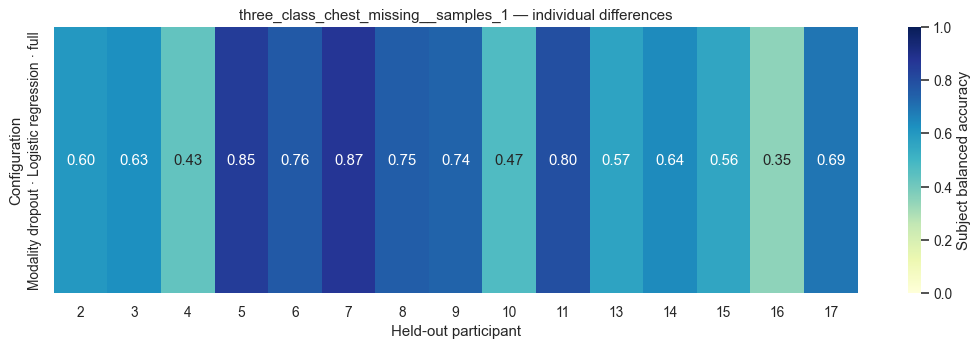

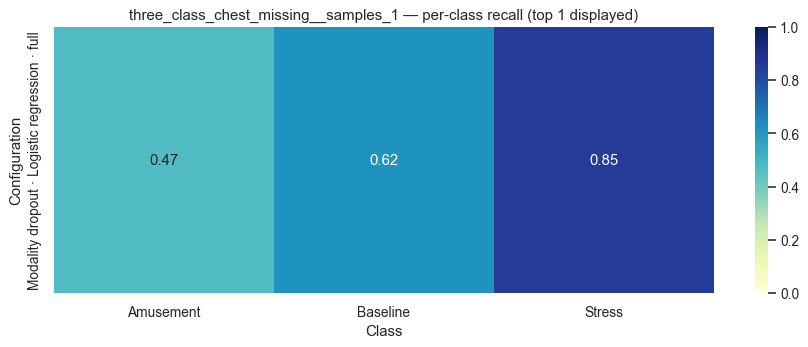

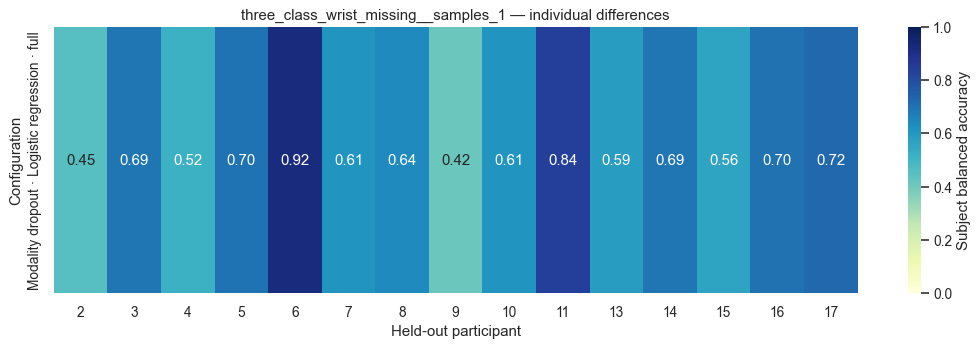

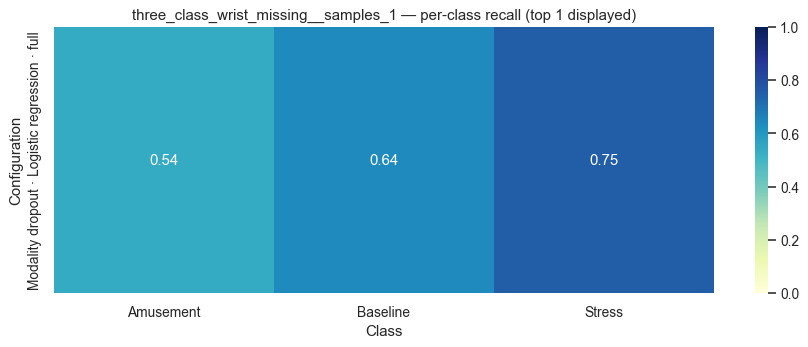

In [4]:
# At-a-glance full-model grid and subject variability, separated by benchmark group.
for group,g in benchmark.groupby('benchmark_group'):
    regular=g[g.variant.eq('full') & g.site.isin(['chest','wrist','early_fusion'])]
    if not regular.empty:
        matrix=regular.pivot_table(index='model',columns='site',values='BA_mean',aggfunc='first')
        fig,ax=plt.subplots(figsize=(8,max(4,len(matrix)*.65)))
        sns.heatmap(matrix,annot=True,fmt='.3f',vmin=0,vmax=1,cmap='YlGnBu',ax=ax,cbar_kws={'label':'Mean balanced accuracy'})
        ax.set(title=f'{group} — full models',xlabel='Sensor configuration',ylabel='Algorithm')
        fig.tight_layout();show(fig,f'full_model_grid_{safe(group)}.png')
    keys=list(g.experiment)
    by_subject=fold_metrics[fold_metrics.experiment.isin(keys)].pivot(index='experiment',columns='subject_id',values='balanced_accuracy').reindex(keys)
    fig,ax=plt.subplots(figsize=(12,max(4,len(keys)*.28)))
    sns.heatmap(by_subject,vmin=0,vmax=1,cmap='YlGnBu',annot=len(keys)<=15,fmt='.2f',
        yticklabels=[experiments[key]['label'] for key in keys],ax=ax,cbar_kws={'label':'Subject balanced accuracy'})
    ax.set(title=f'{group} — individual differences',xlabel='Held-out participant',ylabel='Configuration')
    fig.tight_layout();show(fig,f'subject_heatmap_{safe(group)}.png')
    # The top display limit affects figure size only; full metrics remain in CSV.
    shown=list(g.nlargest(TOP_DISPLAY,'BA_mean').experiment)
    recall=class_metrics[class_metrics.experiment.isin(shown)].groupby(['experiment','class_name']).recall.mean().unstack().reindex(shown)
    fig,ax=plt.subplots(figsize=(10,max(4,len(shown)*.4)))
    sns.heatmap(recall,vmin=0,vmax=1,annot=True,fmt='.2f',cmap='YlGnBu',yticklabels=[experiments[key]['label'] for key in shown],ax=ax)
    ax.set(title=f'{group} — per-class recall (top {len(shown)} displayed)',xlabel='Class',ylabel='Configuration')
    fig.tight_layout();show(fig,f'recall_heatmap_{safe(group)}.png')


## Sensitivity curves and parsimony

All thresholds are displayed. A reduced configuration is not promoted to the primary analysis because of a favorable score. Lines are descriptive; a smaller feature set does not guarantee better performance. Feature counts are input/retained counts recorded by the training workflow, not counts of physiologically independent variables.

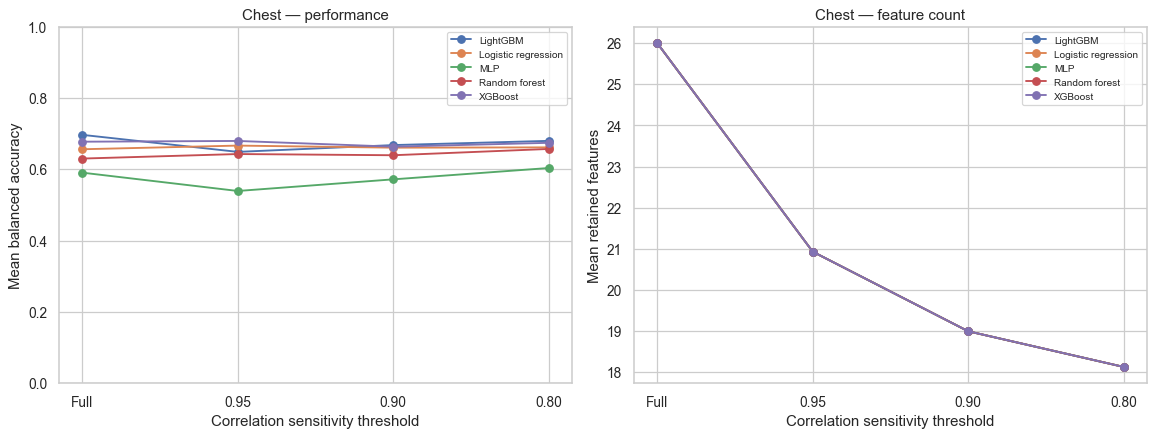

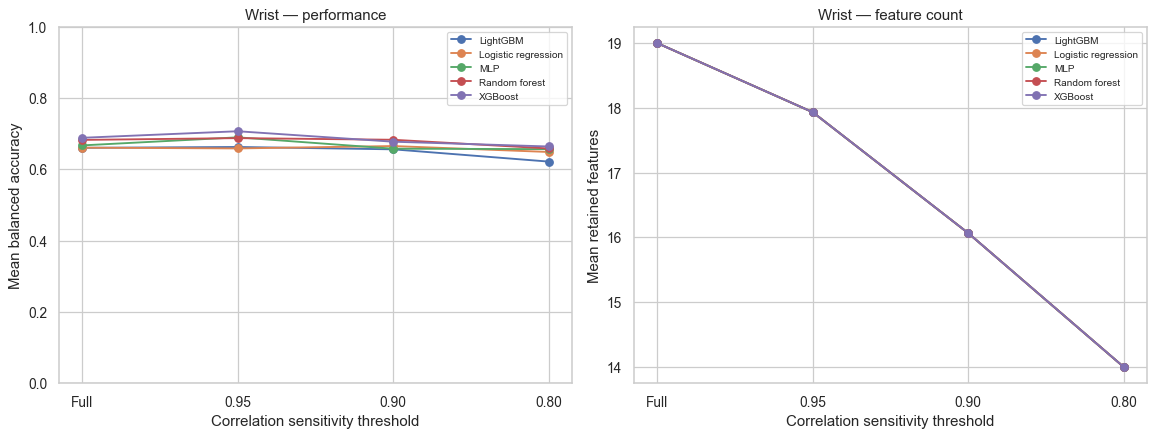

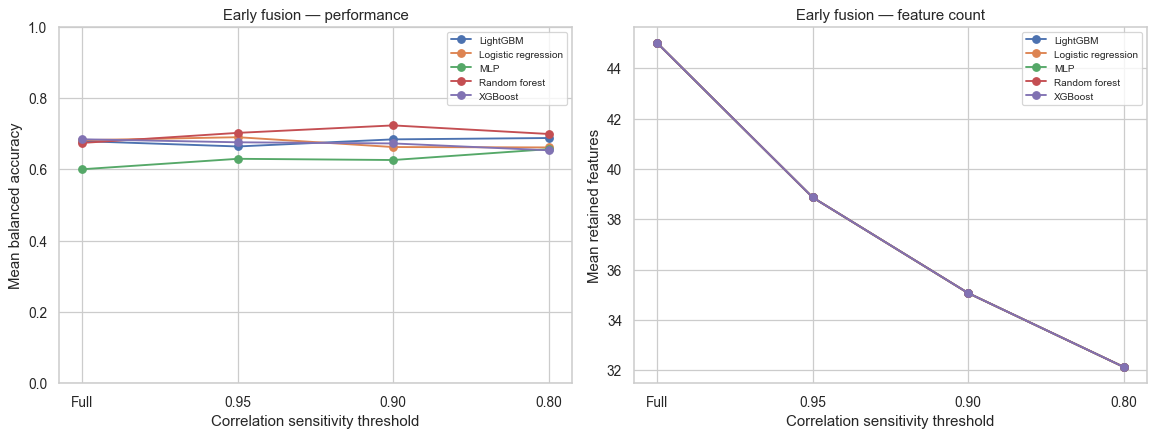

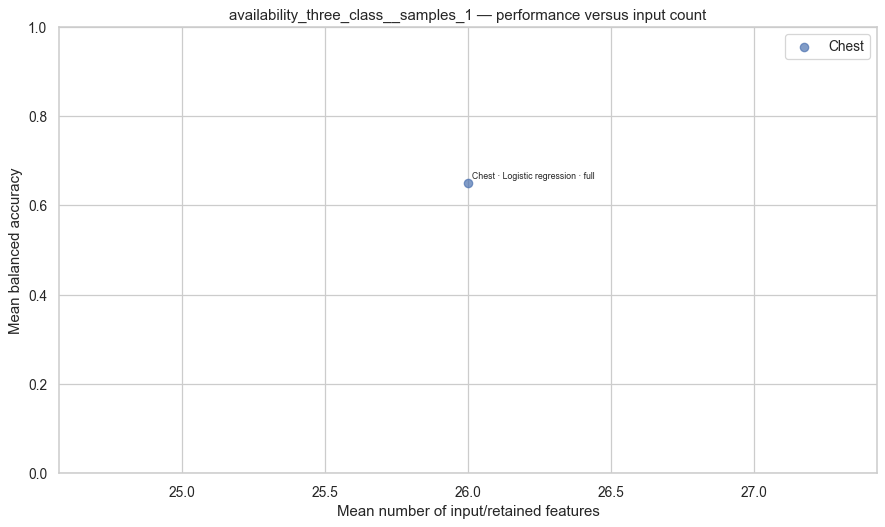

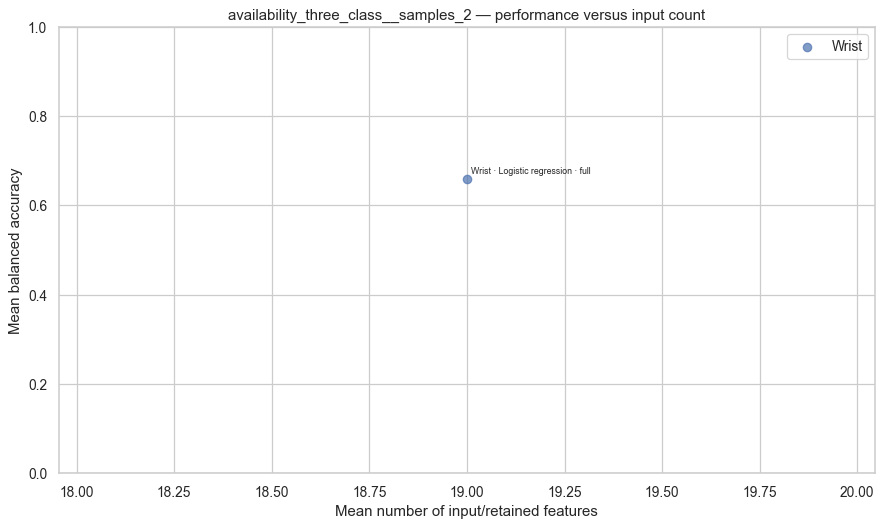

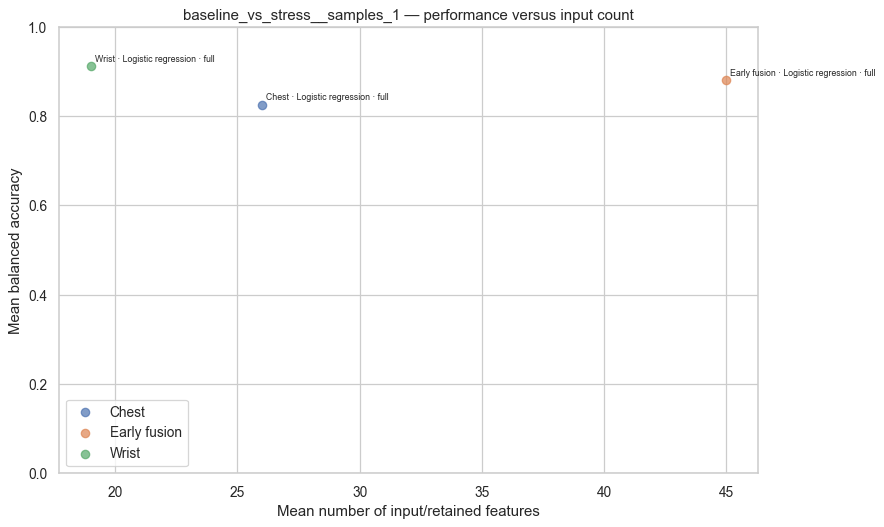

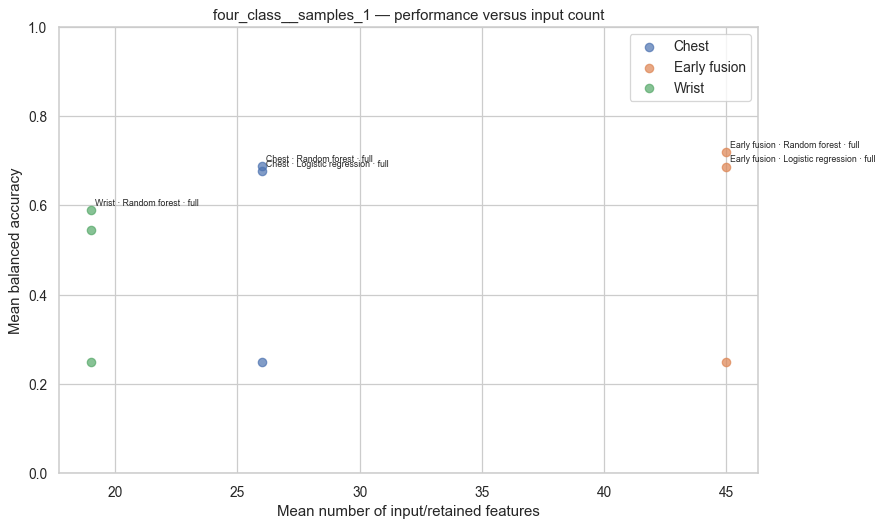

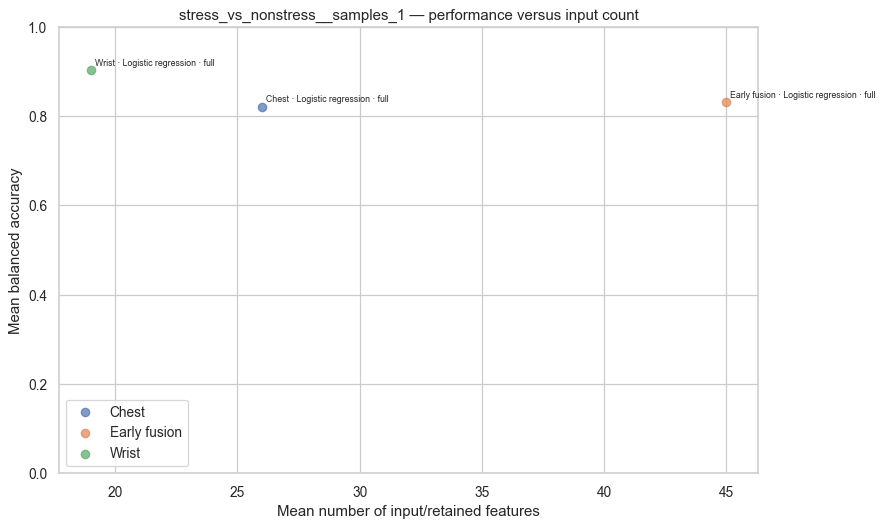

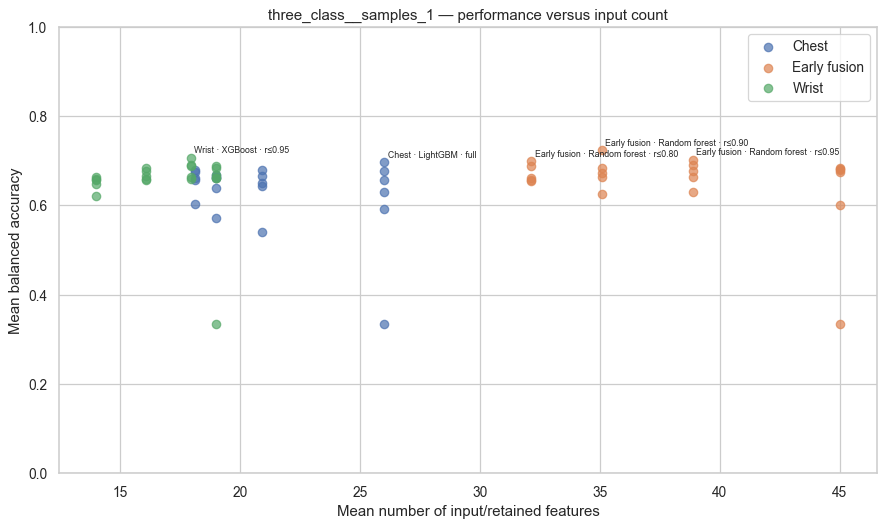

In [5]:
sensitivity_keys=[k for k in experiments if k.startswith('sensitivity_') or any(a['retained']==k for a in aliases)]
sensitivity_summary=benchmark[benchmark.experiment.isin(sensitivity_keys)].copy()
for site in ['chest','wrist','early_fusion']:
    g=sensitivity_summary[sensitivity_summary.site.eq(site)]
    if g.empty:continue
    fig,axes=plt.subplots(1,2,figsize=(13,5))
    for model,rows in g.groupby('model'):
        rows=rows.copy();rows['x']=rows.variant.map({'full':0,'reduced_0.95':1,'reduced_0.90':2,'reduced_0.80':3})
        rows=rows.sort_values('x')
        axes[0].plot(rows.x,rows.BA_mean,'o-',label=MODELS.get(model,model))
        axes[1].plot(rows.x,rows.mean_n_features,'o-',label=MODELS.get(model,model))
    for ax in axes:ax.set(xticks=[0,1,2,3],xticklabels=['Full','0.95','0.90','0.80'],xlabel='Correlation sensitivity threshold');ax.legend(fontsize=8)
    axes[0].set(ylabel='Mean balanced accuracy',title=f'{SITES[site]} — performance',ylim=(0,1))
    axes[1].set(ylabel='Mean retained features',title=f'{SITES[site]} — feature count')
    fig.tight_layout();show(fig,f'sensitivity_{site}.png')

for group,g in benchmark.groupby('benchmark_group'):
    valid=g.dropna(subset=['mean_n_features'])
    if valid.empty:continue
    fig,ax=plt.subplots(figsize=(10,6))
    for site,rows in valid.groupby('site'):
        ax.scatter(rows.mean_n_features,rows.BA_mean,label=SITES.get(site,site),s=45,alpha=.7)
    # Annotate a small set for readability; all points and tables remain available.
    for row in valid.nlargest(5,'BA_mean').itertuples():ax.annotate(row.label,(row.mean_n_features,row.BA_mean),fontsize=7,xytext=(3,4),textcoords='offset points')
    ax.set(title=f'{group} — performance versus input count',xlabel='Mean number of input/retained features',ylabel='Mean balanced accuracy',ylim=(0,1))
    ax.legend();fig.tight_layout();show(fig,f'parsimony_{safe(group)}.png')


## Targeted paired comparisons

These comparisons were chosen after inspecting earlier results and are exploratory. Only identical sample fingerprints and identical participants are admitted. All eligible subjects enter the paired bootstrap. Intervals are conditional and unadjusted for multiple comparisons: no significance stars or winner declaration are produced. A group of many pairwise tests should not be treated as independent confirmation.

,A,B,n_subjects,difference_pp,low_pp,high_pp,subjects_improved,subjects_worse,subjects_tied
0,late_fusion_both_present,sensitivity_early_fusion_random_forest_reduced...,15,0.959455,-6.716330,7.460528,10,5,0
1,sensitivity_early_fusion_random_forest_reduced...,confirmatory_wrist_random_forest,15,4.068052,-2.038601,10.223184,11,4,0
2,sensitivity_early_fusion_random_forest_reduced...,sensitivity_wrist_xgboost_reduced_0.95,15,1.641230,-4.989180,9.069168,7,8,0


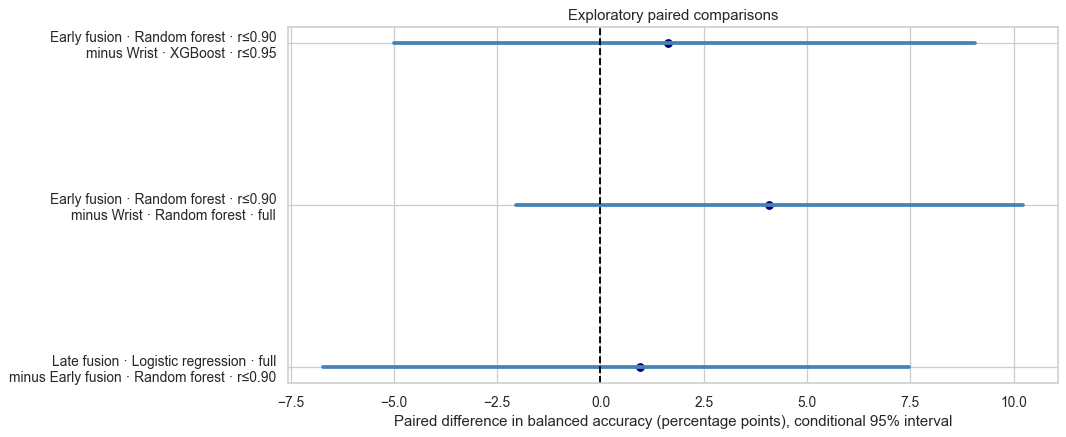

In [6]:
# A minus B: positive differences favor A. Names refer to saved experiments.
REQUESTED_COMPARISONS=[
 ('late_fusion_both_present','sensitivity_early_fusion_random_forest_reduced_0.90'),
 ('sensitivity_early_fusion_random_forest_reduced_0.90','confirmatory_wrist_random_forest'),
 ('sensitivity_early_fusion_random_forest_reduced_0.90','sensitivity_wrist_xgboost_reduced_0.95'),
]
alias_map={row['alias']:row['retained'] for row in aliases}
paired_results=[];paired_subjects=[];comparison_audit=[]
for a,b in REQUESTED_COMPARISONS:
    a=alias_map.get(a,a);b=alias_map.get(b,b)
    if a not in experiments or b not in experiments:
        comparison_audit.append(dict(A=a,B=b,status='missing experiment'));continue
    ma,mb=experiments[a],experiments[b]
    if ma['task']!=mb['task'] or ma['signature']!=mb['signature']:
        comparison_audit.append(dict(A=a,B=b,status='incompatible task or windows'));continue
    x=fold_metrics[fold_metrics.experiment.eq(a)].set_index('subject_id').balanced_accuracy
    y=fold_metrics[fold_metrics.experiment.eq(b)].set_index('subject_id').balanced_accuracy
    if set(x.index)!=set(y.index):raise ValueError('Paired comparison participant mismatch')
    d=x.sort_index()-y.sort_index();low,high=ci(d)
    paired_results.append(dict(A=a,B=b,n_subjects=len(d),difference_pp=100*d.mean(),low_pp=100*low,high_pp=100*high,
        subjects_improved=int((d>1e-12).sum()),subjects_worse=int((d< -1e-12).sum()),subjects_tied=int((d.abs()<=1e-12).sum())))
    paired_subjects.extend([dict(A=a,B=b,subject_id=int(sid),difference_pp=100*value) for sid,value in d.items()])
paired=pd.DataFrame(paired_results);display(paired)
paired.to_csv(OUT/'targeted_paired_comparisons.csv',index=False)
pd.DataFrame(paired_subjects).to_csv(OUT/'targeted_subject_differences.csv',index=False)
pd.DataFrame(comparison_audit).to_csv(OUT/'paired_comparison_audit.csv',index=False)
if not paired.empty:
    fig,ax=plt.subplots(figsize=(12,5))
    for i,row in enumerate(paired.itertuples()):
        ax.plot([row.low_pp,row.high_pp],[i,i],color='steelblue',linewidth=3);ax.scatter(row.difference_pp,i,color='navy')
    ax.axvline(0,color='black',linestyle='--')
    ax.set(yticks=range(len(paired)),yticklabels=[f"{experiments[r.A]['label']}\nminus {experiments[r.B]['label']}" for r in paired.itertuples()],
        xlabel='Paired difference in balanced accuracy (percentage points), conditional 95% interval',title='Exploratory paired comparisons')
    fig.tight_layout();show(fig,'targeted_paired_comparisons.png')


## Precision, recall and F1: like-for-like visual comparisons

Metrics are first computed separately for each held-out participant, then averaged equally across participants. Macro metrics give equal weight to classes. Recall macro equals balanced accuracy here because every evaluated participant has all required classes; the duplicated view is intentional for readability. Precision/F1 with no predicted examples use zero, consistently with the earlier workflow.

Full-model charts compare only the same task and exact same OOF sample set. Sensitivity charts compare full and reduced variants of the same algorithm and modality. Class-specific plots are separated by experiment group, modality and variant. Charts summarize observed means; apparent bar differences are not statistical significance tests. Complete tables are retained and no winner is automatically selected.


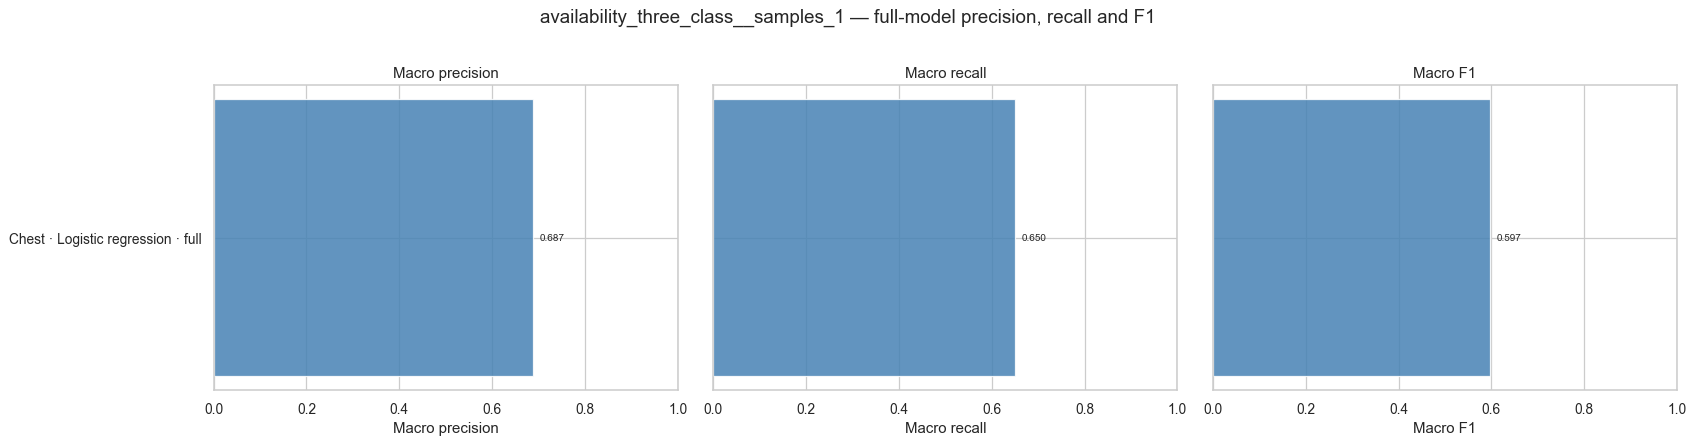

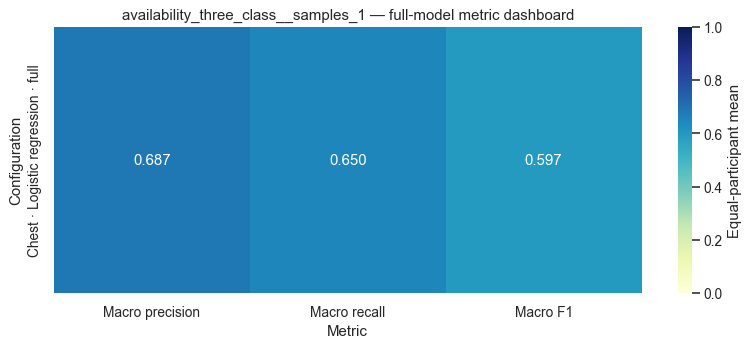

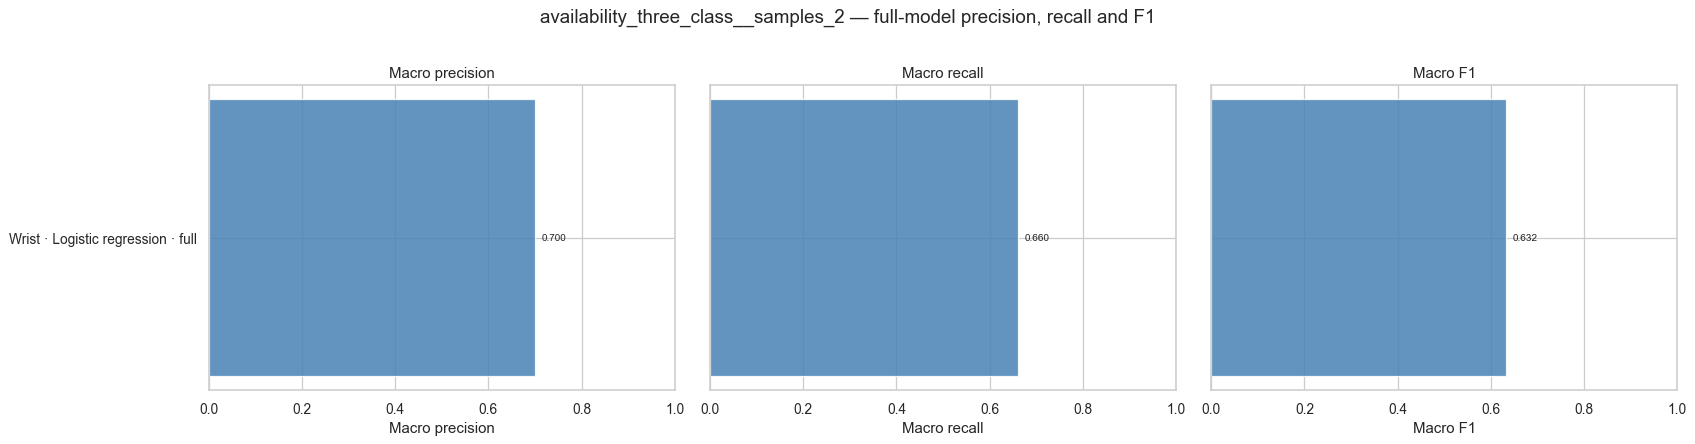

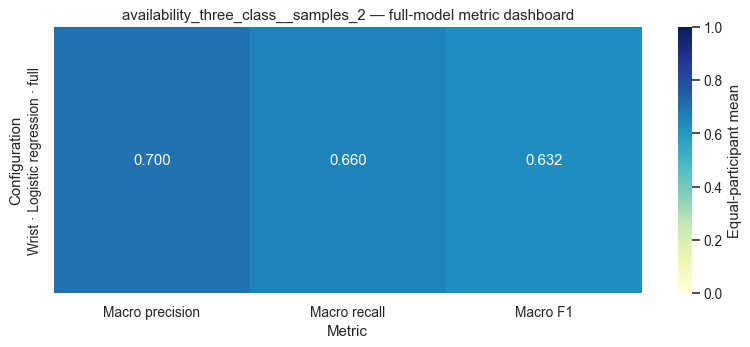

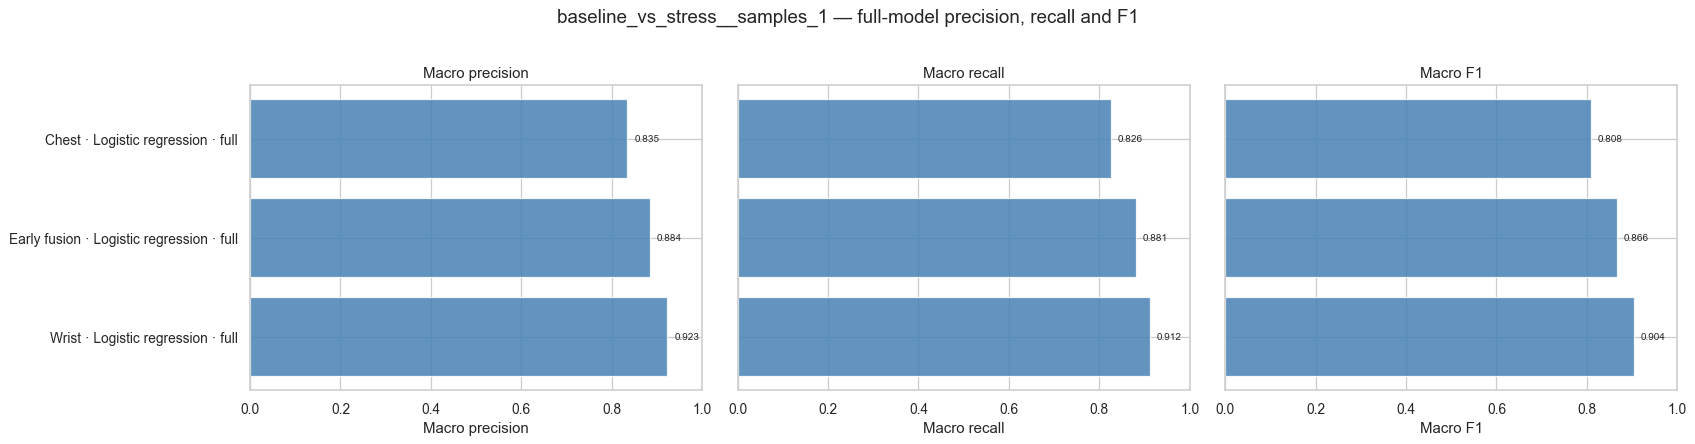

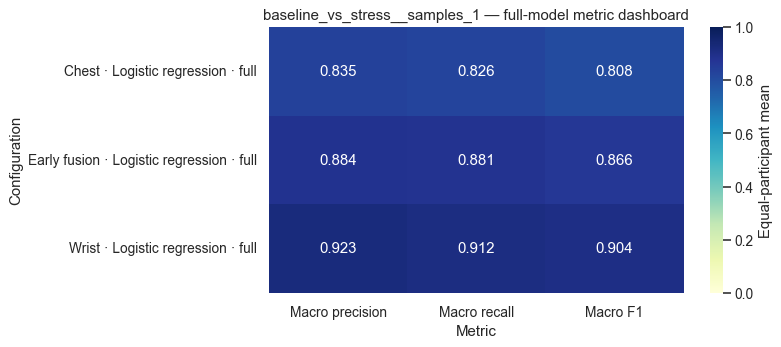

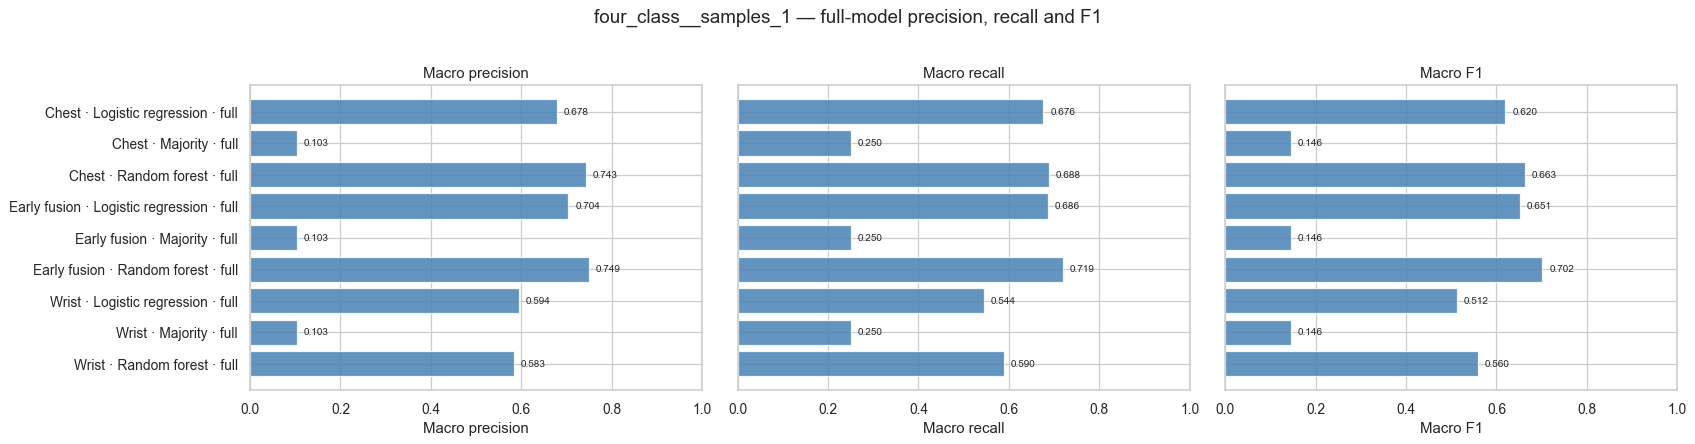

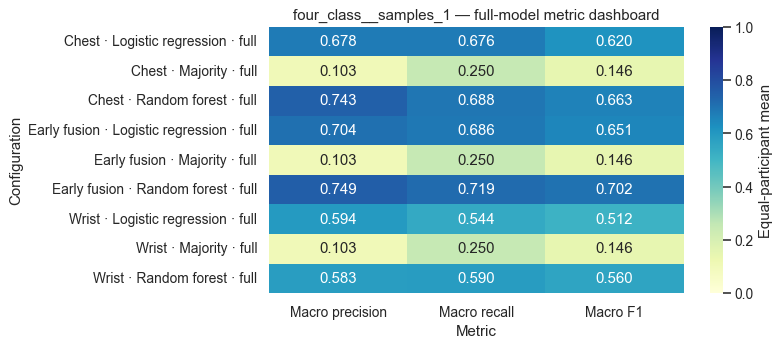

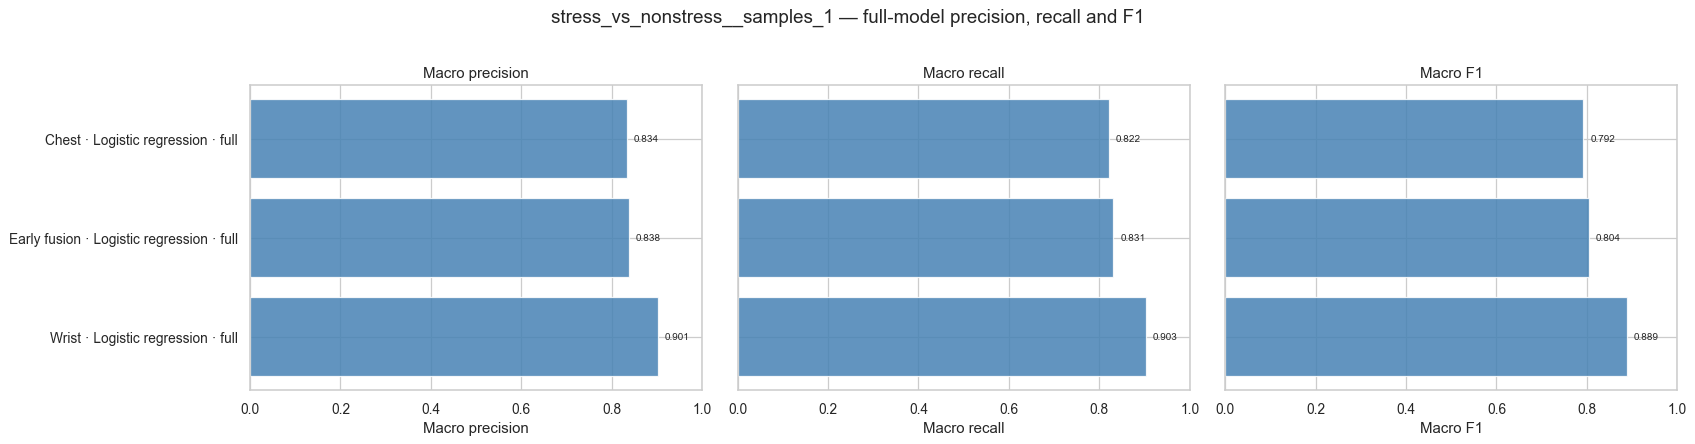

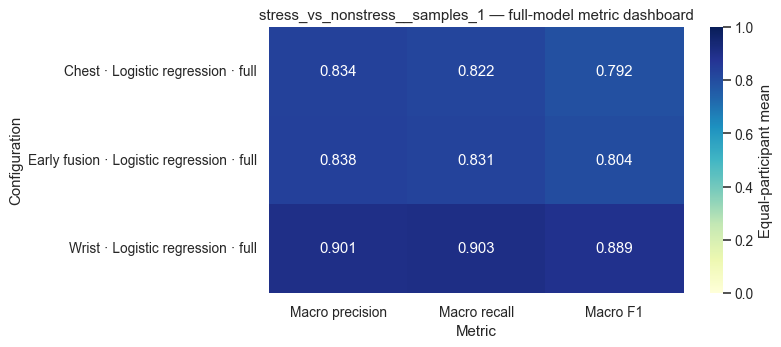

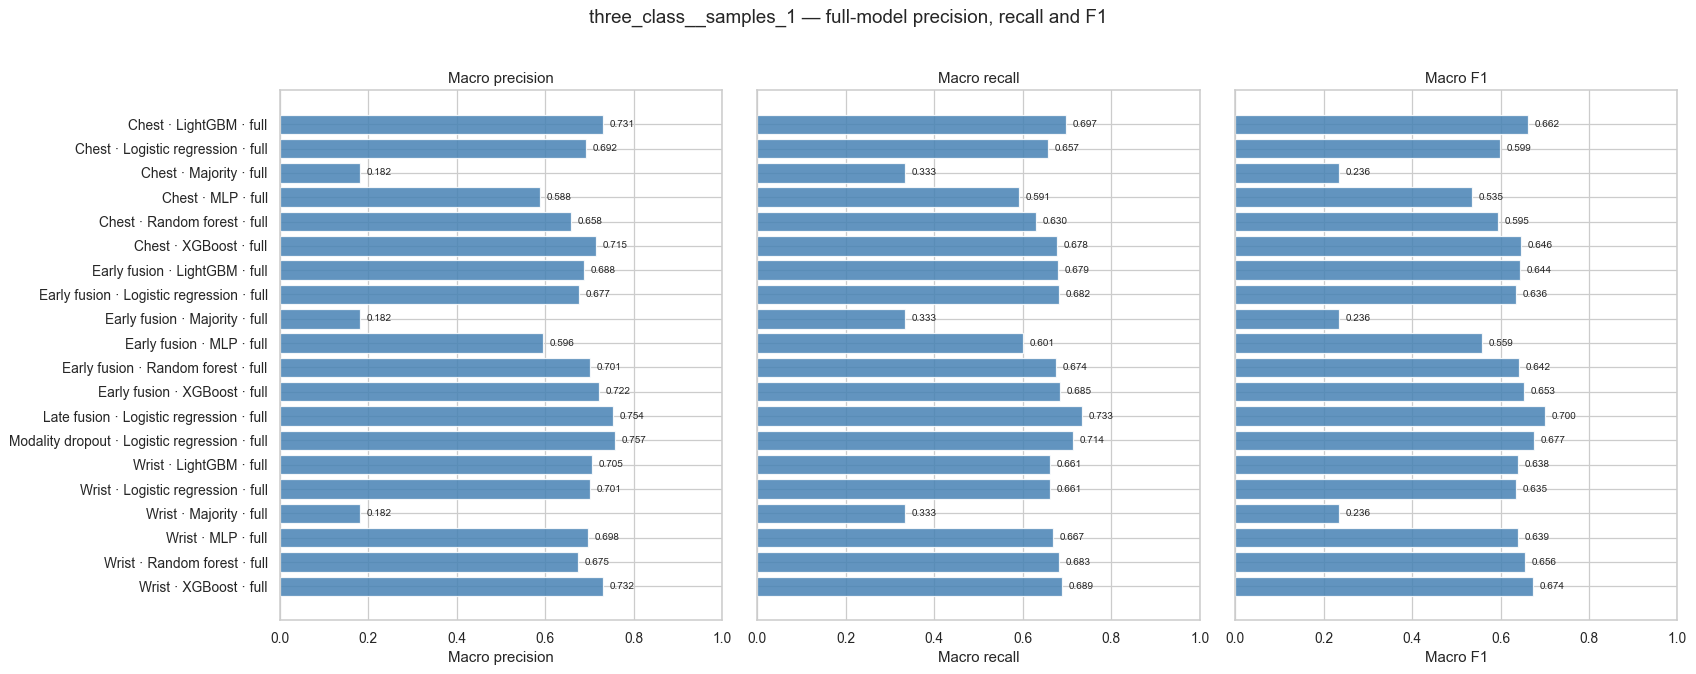

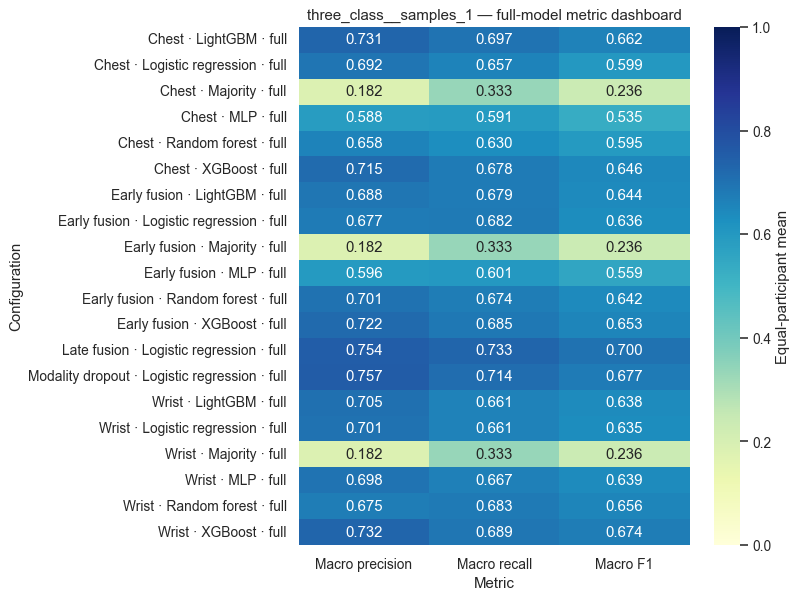

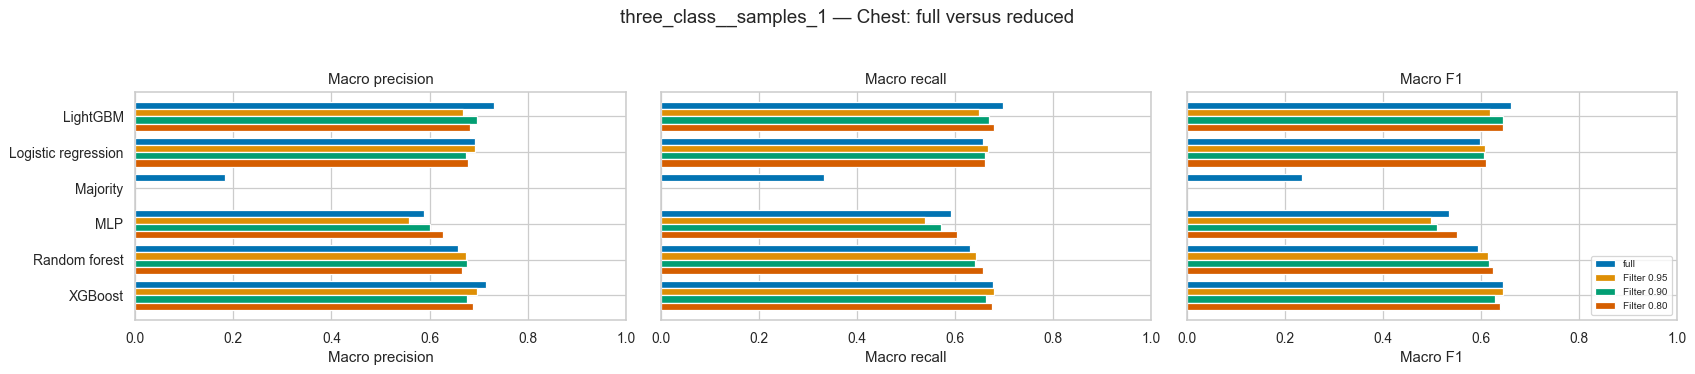

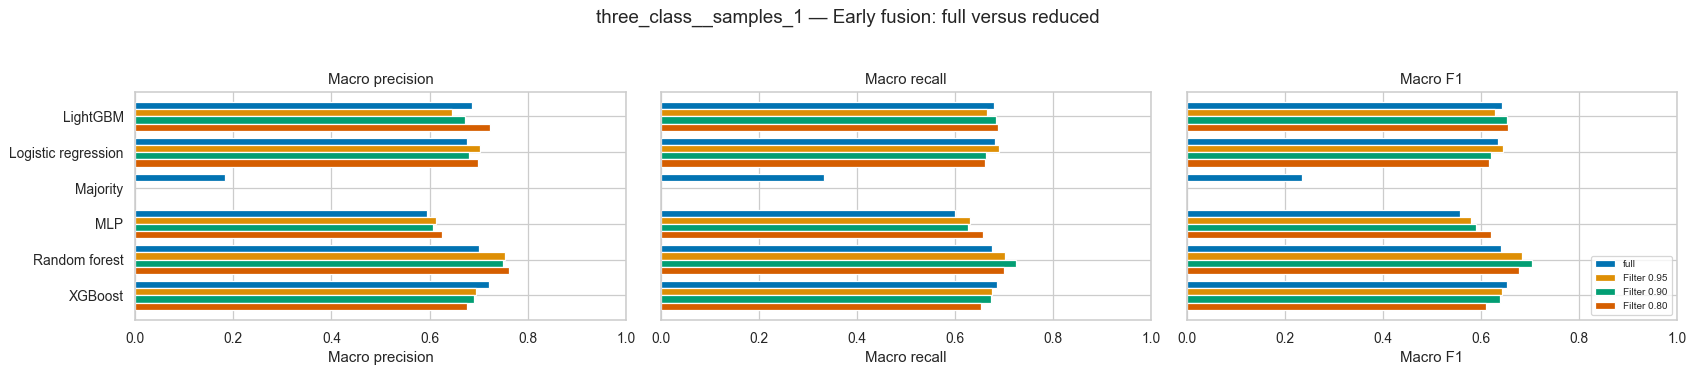

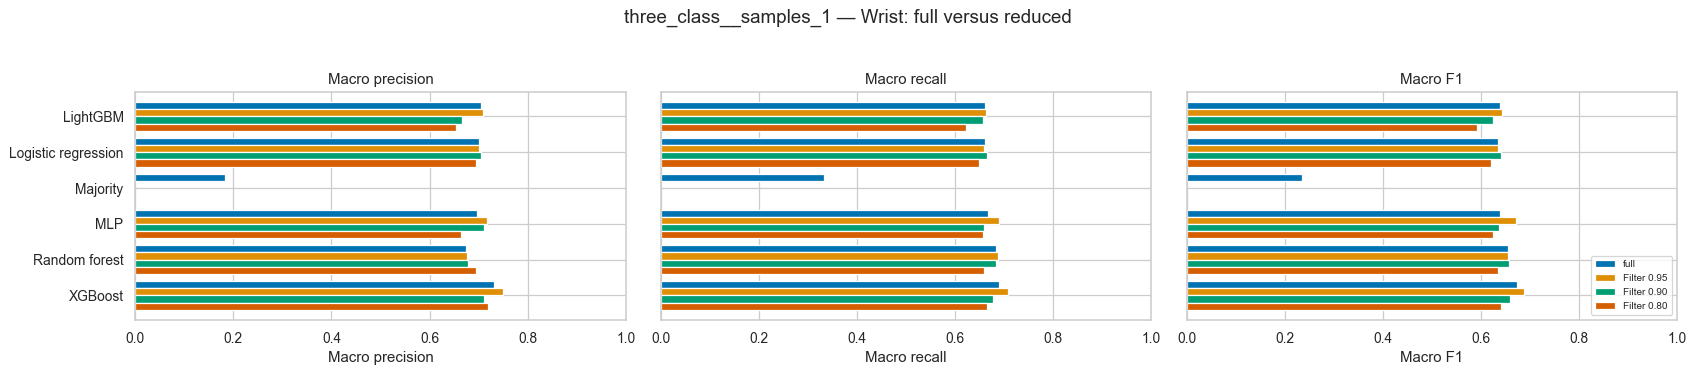

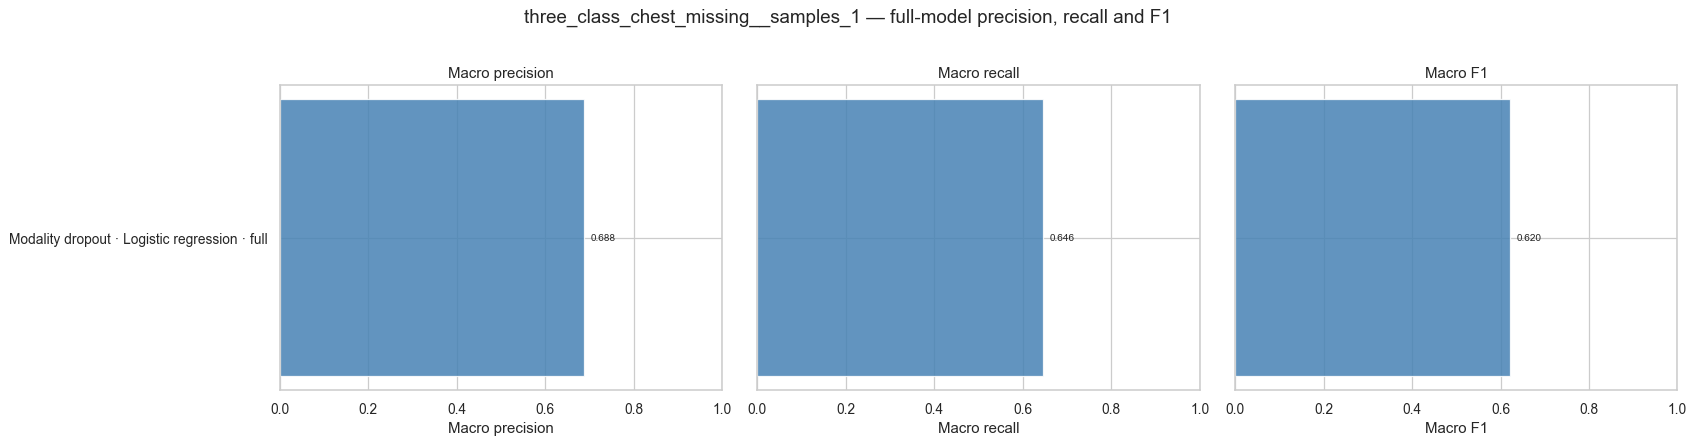

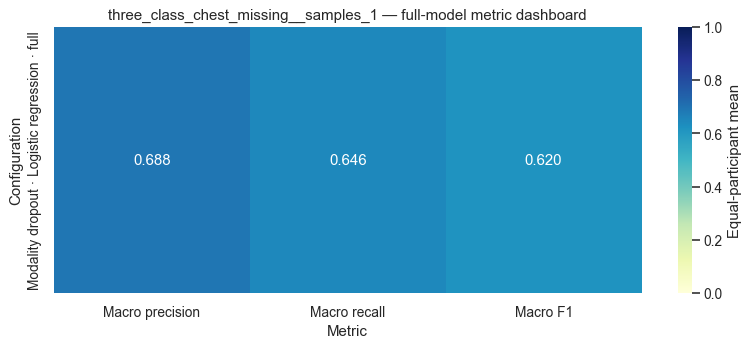

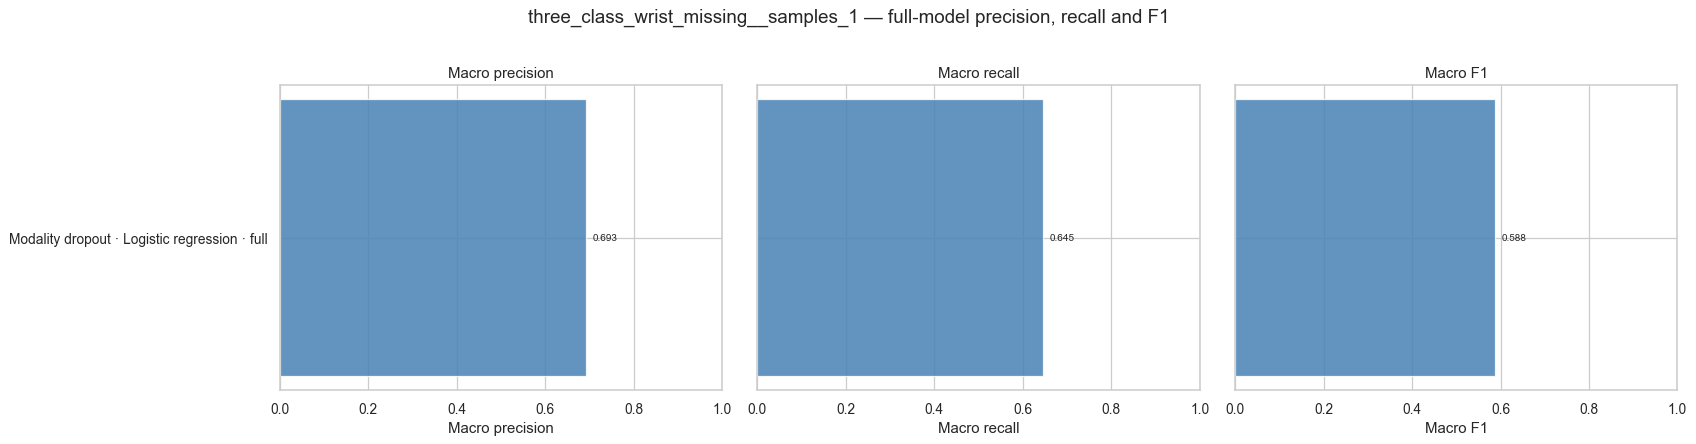

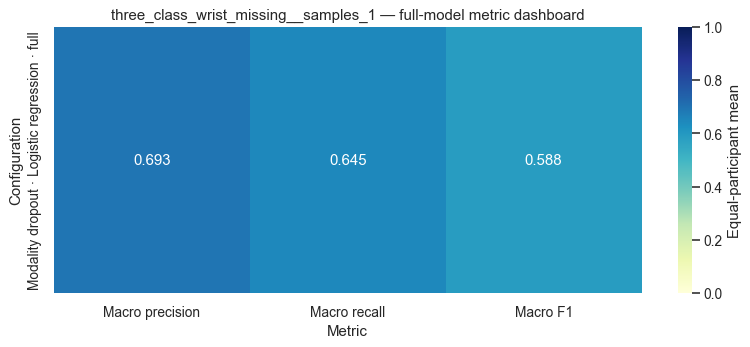

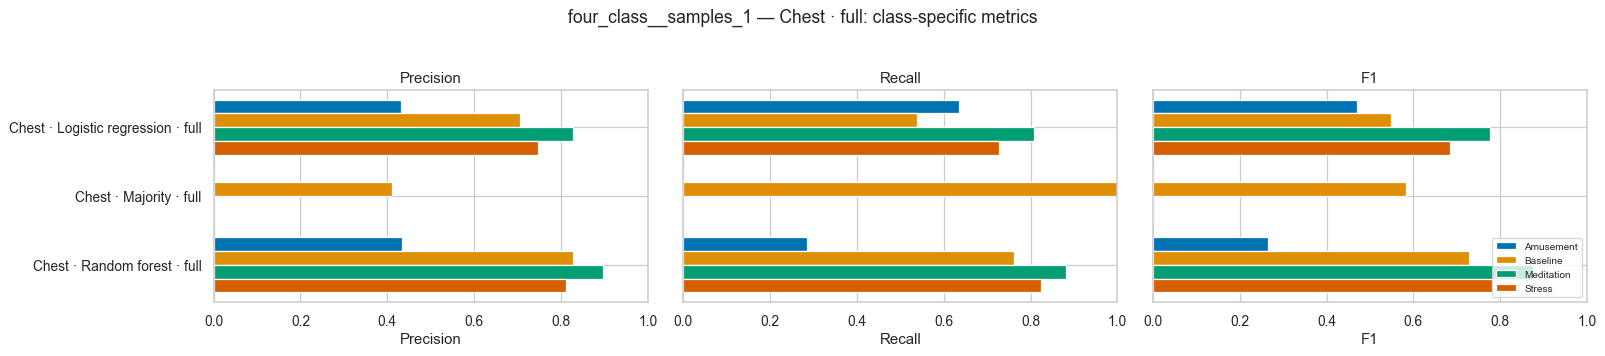

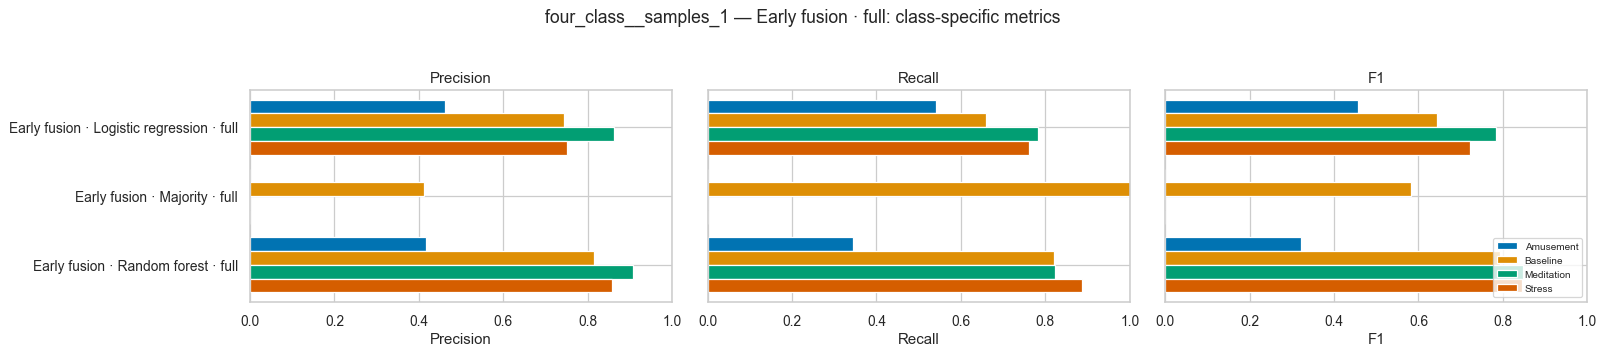

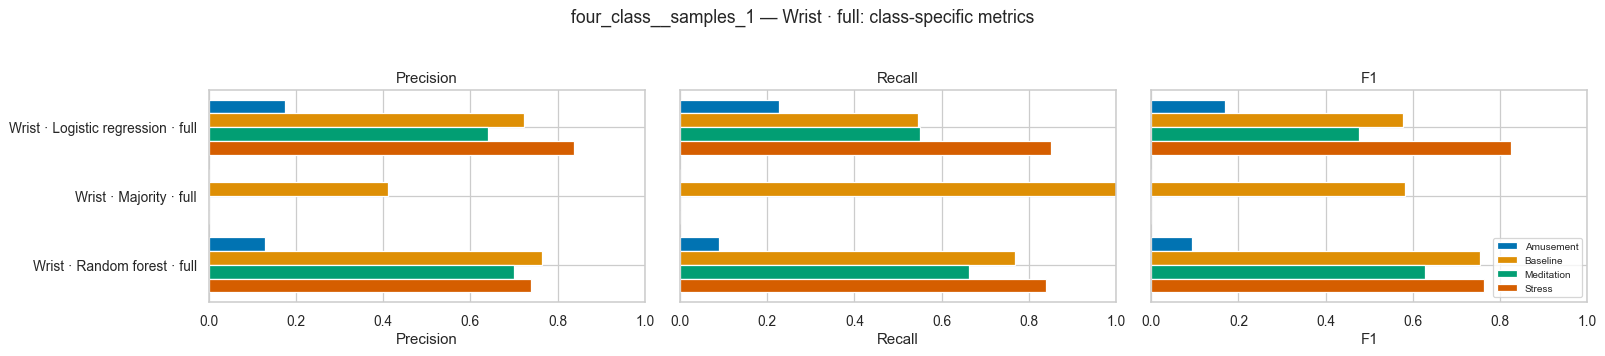

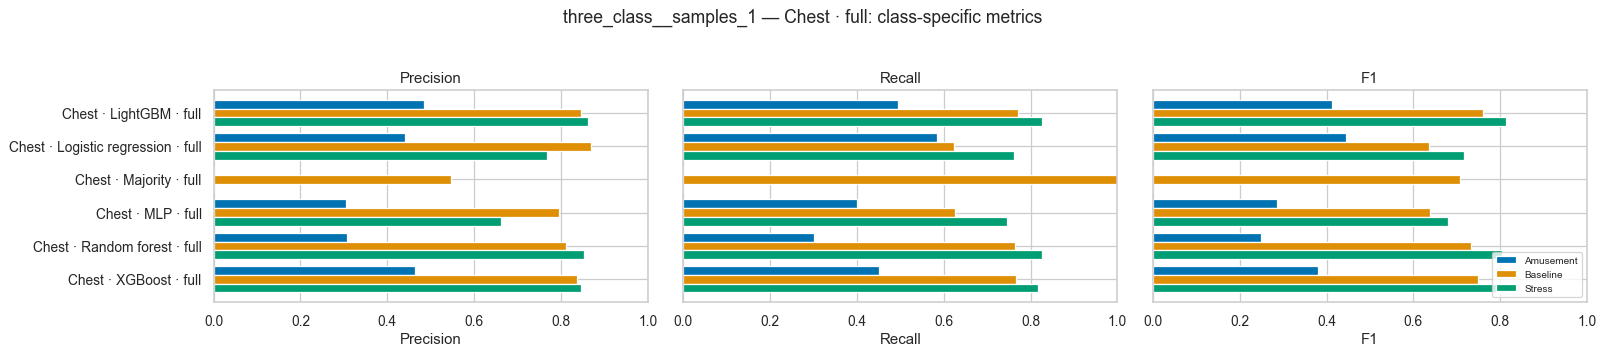

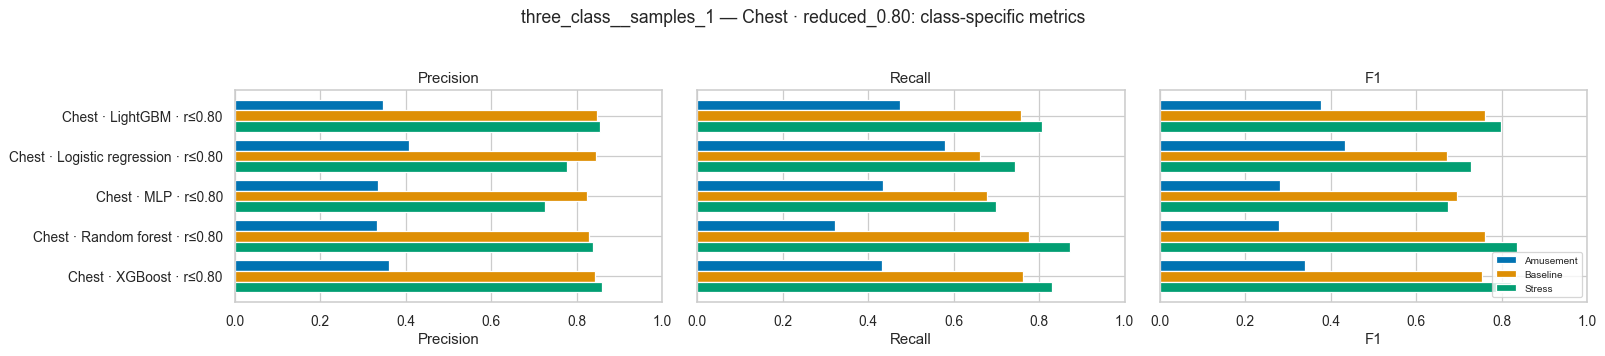

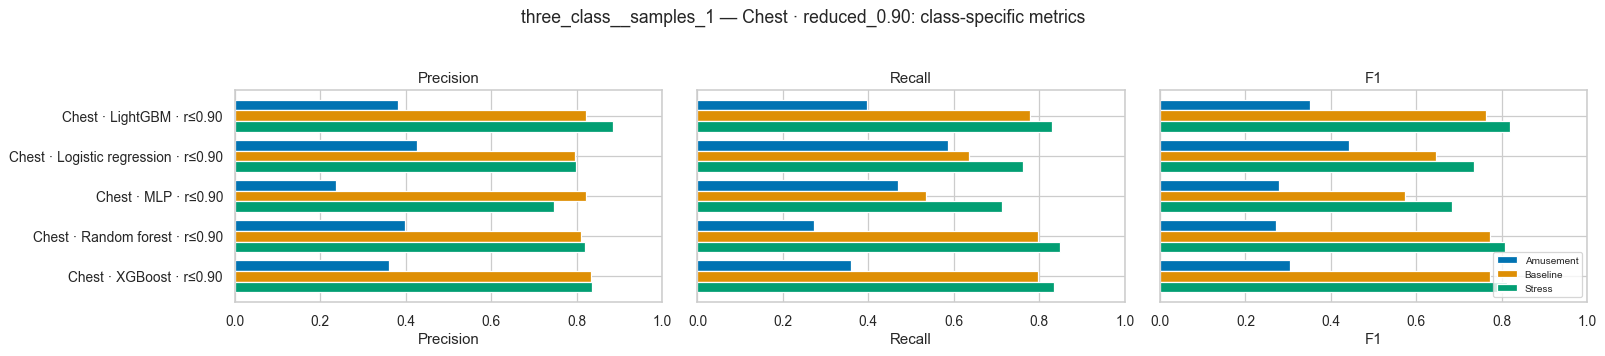

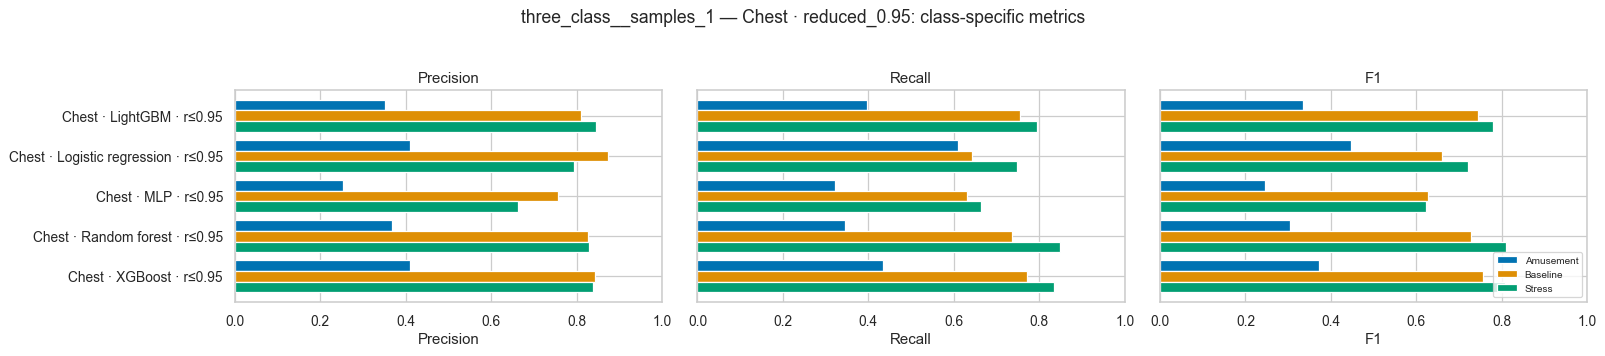

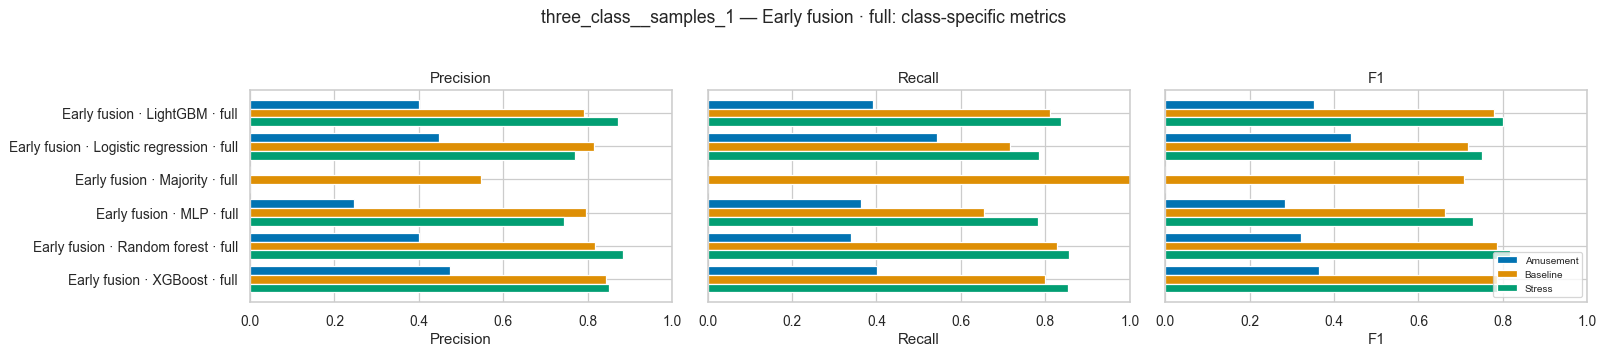

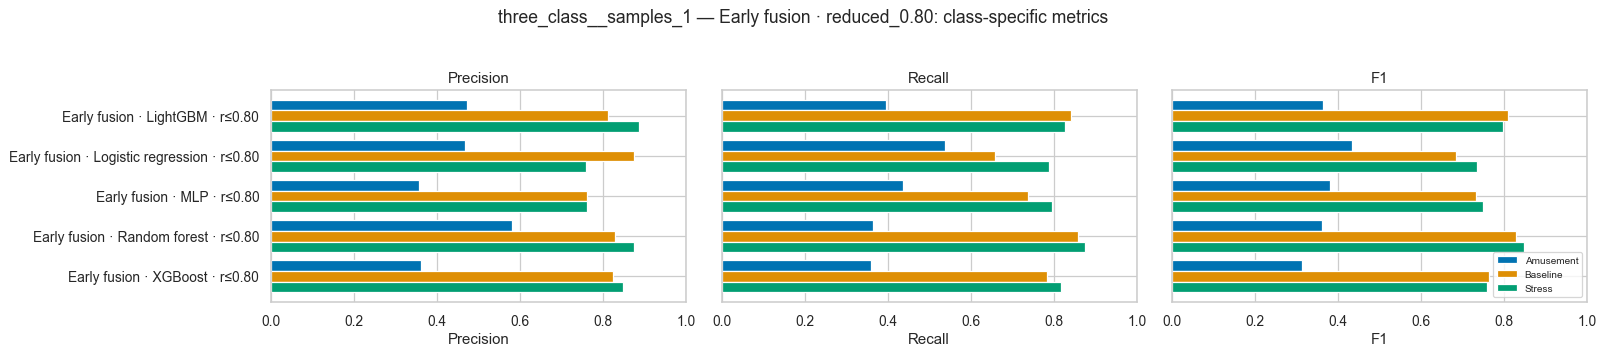

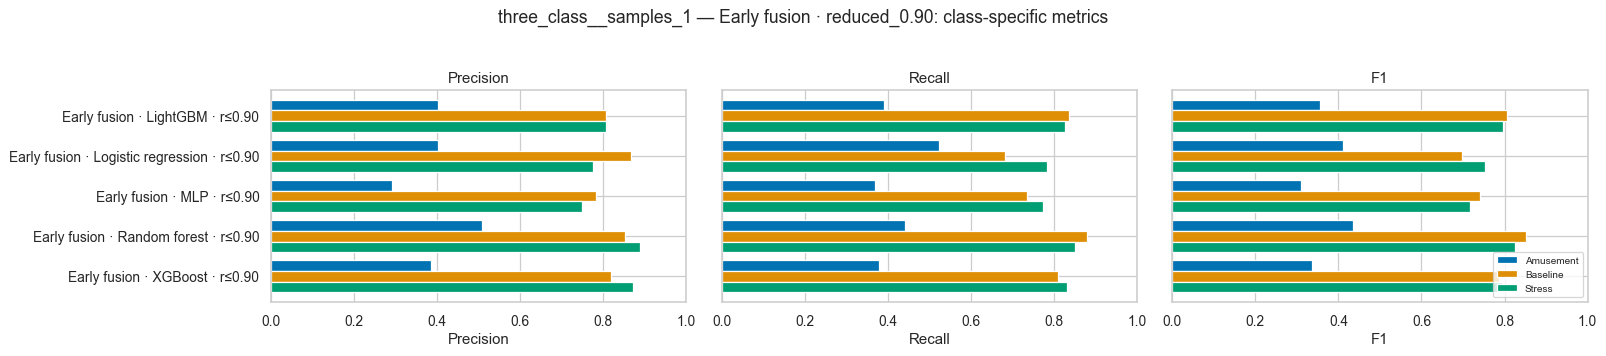

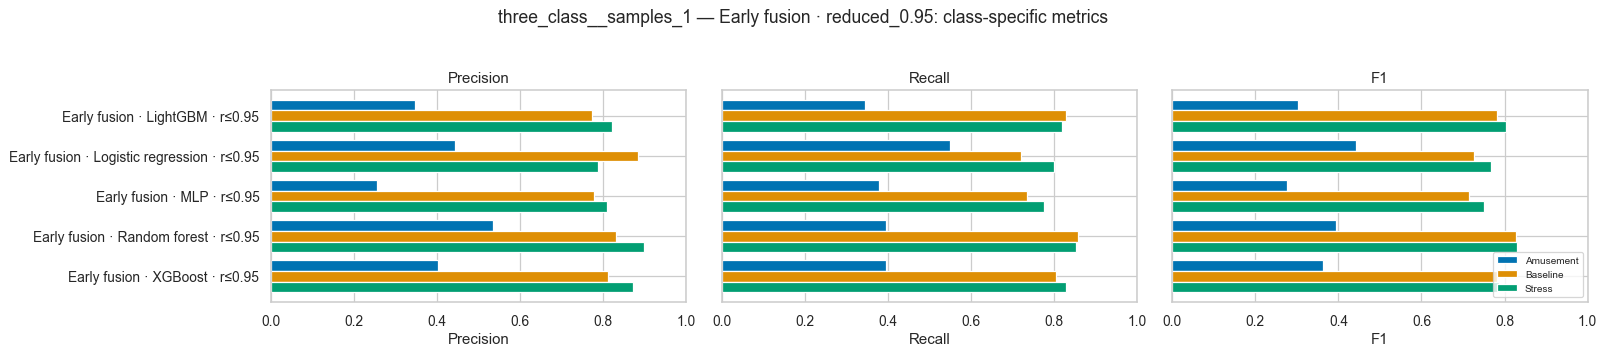

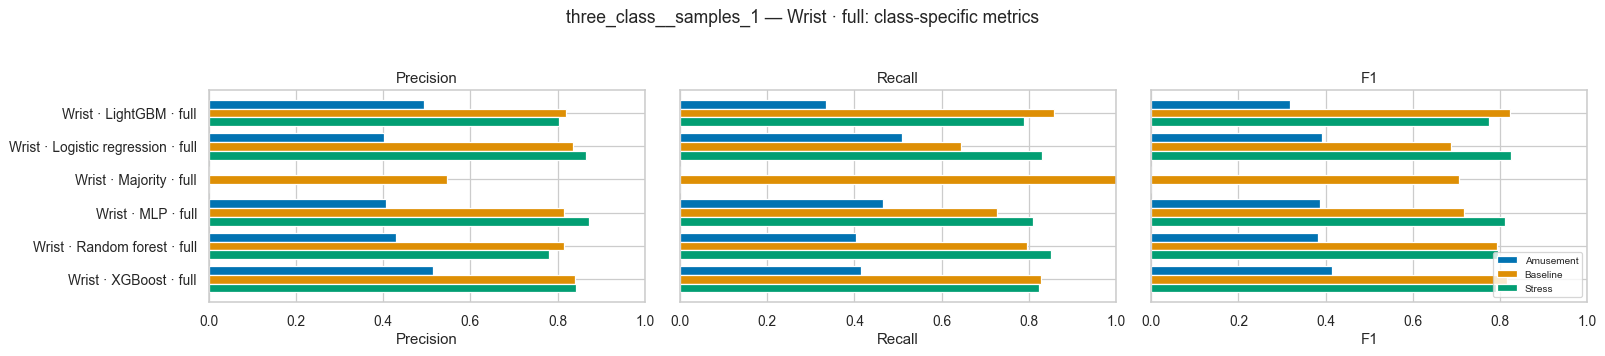

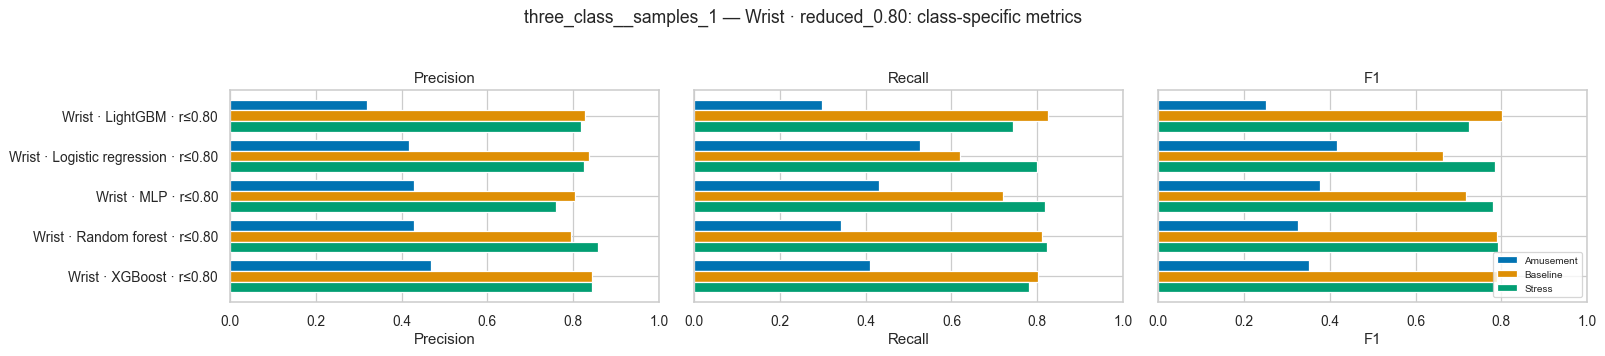

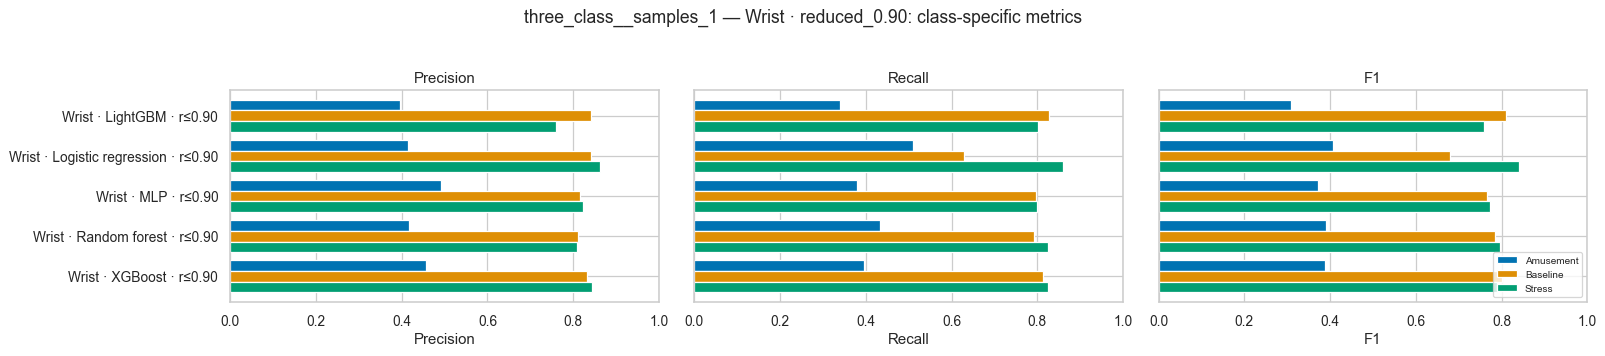

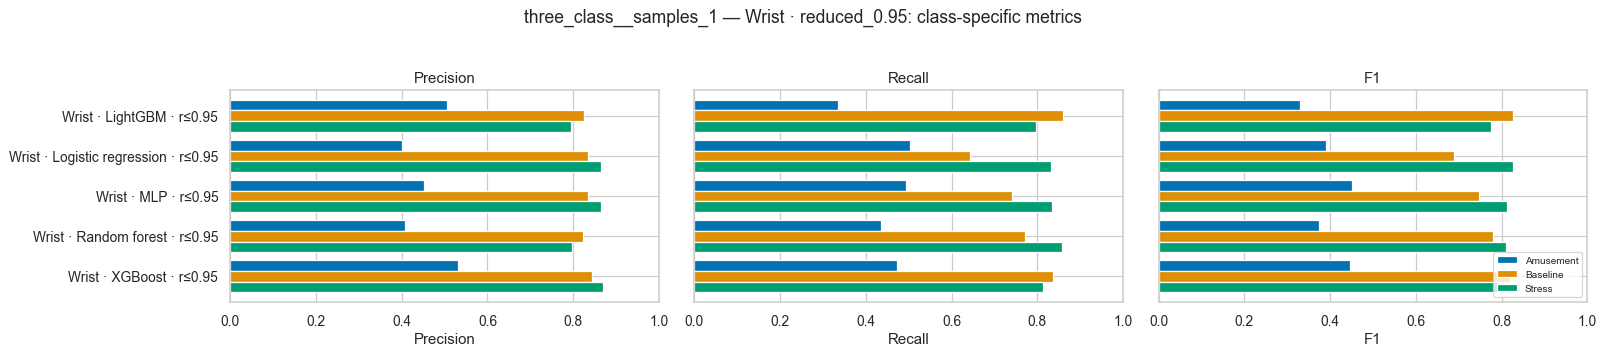

,experiment,label,task,site,model,variant,role,benchmark_group,precision_macro,recall_macro,macro_f1
0,secondary_availability_three_class_chest,Chest · Logistic regression · full,availability_three_class,chest,logistic_regression,full,secondary,availability_three_class__samples_1,0.686889,0.649898,0.596704
1,secondary_availability_three_class_wrist,Wrist · Logistic regression · full,availability_three_class,wrist,logistic_regression,full,secondary,availability_three_class__samples_2,0.700051,0.660100,0.631974
2,secondary_baseline_vs_stress_wrist,Wrist · Logistic regression · full,baseline_vs_stress,wrist,logistic_regression,full,secondary,baseline_vs_stress__samples_1,0.923086,0.912178,0.904227
3,secondary_baseline_vs_stress_early_fusion,Early fusion · Logistic regression · full,baseline_vs_stress,early_fusion,logistic_regression,full,secondary,baseline_vs_stress__samples_1,0.883860,0.881020,0.866237
4,secondary_baseline_vs_stress_chest,Chest · Logistic regression · full,baseline_vs_stress,chest,logistic_regression,full,secondary,baseline_vs_stress__samples_1,0.834504,0.826078,0.808374
...,...,...,...,...,...,...,...,...,...,...,...
79,confirmatory_chest_majority,Chest · Majority · full,three_class,chest,majority,full,primary,three_class__samples_1,0.182355,0.333333,0.235657
80,confirmatory_early_fusion_majority,Early fusion · Majority · full,three_class,early_fusion,majority,full,primary,three_class__samples_1,0.182355,0.333333,0.235657
81,confirmatory_wrist_majority,Wrist · Majority · full,three_class,wrist,majority,full,primary,three_class__samples_1,0.182355,0.333333,0.235657
82,modality_dropout_chest_missing,Modality dropout · Logistic regression · full,three_class_chest_missing,modality_dropout,logistic_regression,full,exploratory,three_class_chest_missing__samples_1,0.687846,0.646260,0.620393


Precision, recall and F1 comparison figures saved at 300 dpi.


In [7]:
from sklearn.metrics import precision_recall_fscore_support

per_class_rows=[]
for key,meta in experiments.items():
    for sid,g in meta['predictions'].groupby('subject_id'):
        precision,recall,f1,support=precision_recall_fscore_support(
            g.label,g.recomputed_prediction,labels=meta['classes'],average=None,zero_division=0)
        for j,k in enumerate(meta['classes']):
            name=({0:'Non-stress',1:'Stress'}[k] if meta['task']=='stress_vs_nonstress' else CLASS_NAMES.get(k,str(k)))
            per_class_rows.append(dict(experiment=key,subject_id=int(sid),class_name=name,
                precision=float(precision[j]),recall=float(recall[j]),f1=float(f1[j]),support=int(support[j])))
per_class_detail=pd.DataFrame(per_class_rows)
per_class_detail.to_csv(OUT/'precision_recall_f1_per_subject_class.csv',index=False)

macro=fold_metrics.groupby('experiment')[['precision_macro','recall_macro','macro_f1']].mean().reset_index()
macro=benchmark[['experiment','label','task','site','model','variant','role','benchmark_group']].merge(macro,on='experiment',validate='one_to_one')
macro.to_csv(OUT/'precision_recall_f1_macro_summary.csv',index=False)
class_summary=per_class_detail.groupby(['experiment','class_name'])[['precision','recall','f1']].mean().reset_index()
class_summary=class_summary.merge(benchmark[['experiment','label','site','model','variant','benchmark_group']],on='experiment',validate='many_to_one')
class_summary.to_csv(OUT/'precision_recall_f1_class_summary.csv',index=False)

METRICS=[('precision_macro','Macro precision'),('recall_macro','Macro recall'),('macro_f1','Macro F1')]

for group,g in macro.groupby('benchmark_group'):
    full=g[g.variant.eq('full')].copy()
    if not full.empty:
        # Every row is an explicitly named configuration, avoiding ambiguous averaging.
        ordered=full.sort_values(['site','model','experiment'])
        order=ordered.experiment.tolist()
        labels=dict(zip(ordered.experiment,ordered.label))
        fig,axes=plt.subplots(1,3,figsize=(19,max(5,len(order)*.38)),sharey=True)
        for ax,(column,title) in zip(axes,METRICS):
            values=ordered.set_index('experiment').loc[order,column]
            ax.barh(range(len(order)),values,color='steelblue',alpha=.85)
            ax.set(xlim=(0,1),xlabel=title,title=title,yticks=range(len(order)))
            for y,value in enumerate(values):ax.text(min(value+.015,.98),y,f'{value:.3f}',va='center',fontsize=8,ha='right' if value>.94 else 'left')
        axes[0].set_yticklabels([labels[key] for key in order]);axes[0].invert_yaxis()
        fig.suptitle(f'{group} — full-model precision, recall and F1',fontsize=15)
        fig.tight_layout(rect=(0,0,1,.96));show(fig,f'precision_recall_f1_full_{safe(group)}.png')

        # Radar-free heatmap provides a compact overview of all three metrics.
        heat=ordered.set_index('experiment')[[m[0] for m in METRICS]]
        heat.columns=[m[1] for m in METRICS]
        fig,ax=plt.subplots(figsize=(9,max(4,len(order)*.34)))
        sns.heatmap(heat,vmin=0,vmax=1,annot=True,fmt='.3f',cmap='YlGnBu',
            yticklabels=[labels[key] for key in heat.index],ax=ax,cbar_kws={'label':'Equal-participant mean'})
        ax.set(title=f'{group} — full-model metric dashboard',xlabel='Metric',ylabel='Configuration')
        fig.tight_layout();show(fig,f'metric_dashboard_full_{safe(group)}.png')

    # Full vs reduced, faceted by modality and algorithm; only same sample set.
    for site,site_data in g.groupby('site'):
        if not site_data.variant.str.startswith('reduced_').any():continue
        rows=[]
        models=sorted(site_data.model.unique())
        for model in models:
            subset=site_data[site_data.model.eq(model)]
            for variant in ['full','reduced_0.95','reduced_0.90','reduced_0.80']:
                match=subset[subset.variant.eq(variant)]
                if len(match)>1:
                    # Never average independent reruns under a single model name.
                    print(f'Multiple full runs: {group}, {site}, {model}; see experiment-level charts.')
                    continue
                if len(match)==1:rows.append(match.iloc[0])
        if not rows:continue
        compared=pd.DataFrame(rows)
        fig,axes=plt.subplots(1,3,figsize=(19,max(4,len(models)*.7)),sharey=True)
        variants=[v for v in ['full','reduced_0.95','reduced_0.90','reduced_0.80'] if v in set(compared.variant)]
        colors=sns.color_palette('colorblind',len(variants));width=.8/max(1,len(variants))
        y=np.arange(len(models))
        for ax,(metric,title) in zip(axes,METRICS):
            for i,variant in enumerate(variants):
                vals=compared[compared.variant.eq(variant)].set_index('model')[metric].reindex(models)
                ax.barh(y+(i-(len(variants)-1)/2)*width,vals,height=width,color=colors[i],label=variant.replace('reduced_','Filter '))
            ax.set(xlim=(0,1),xlabel=title,title=title,yticks=y)
        axes[0].set_yticklabels([MODELS.get(m,m) for m in models]);axes[0].invert_yaxis()
        axes[-1].legend(loc='lower right',fontsize=8)
        fig.suptitle(f'{group} — {SITES.get(site,site)}: full versus reduced',fontsize=15)
        fig.tight_layout(rect=(0,0,1,.94));show(fig,f'precision_recall_f1_sensitivity_{safe(group)}_{site}.png')

# Compare algorithms within the same modality AND filtering variant, class by class.
for (group,site,variant),g in class_summary.groupby(['benchmark_group','site','variant']):
    if g.experiment.nunique()<2:continue
    order=list(g.drop_duplicates('experiment').sort_values(['model','experiment']).experiment)
    label_map=dict(zip(g.experiment,g.label))
    classes=list(g.class_name.unique())
    fig,axes=plt.subplots(1,3,figsize=(18,max(4,len(order)*.65)),sharey=True)
    y=np.arange(len(order));height=.8/len(classes);palette=sns.color_palette('colorblind',len(classes))
    for ax,(metric,title) in zip(axes,[('precision','Precision'),('recall','Recall'),('f1','F1')]):
        for j,name in enumerate(classes):
            values=g[g.class_name.eq(name)].set_index('experiment')[metric].reindex(order)
            ax.barh(y+(j-(len(classes)-1)/2)*height,values,height=height,color=palette[j],label=name)
        ax.set(xlim=(0,1),xlabel=title,title=title,yticks=y)
    axes[0].set_yticklabels([label_map[key] for key in order]);axes[0].invert_yaxis();axes[-1].legend(fontsize=8,loc='lower right')
    fig.suptitle(f'{group} — {SITES.get(site,site)} · {variant}: class-specific metrics',fontsize=14)
    fig.tight_layout(rect=(0,0,1,.94));show(fig,f'precision_recall_f1_classes_{safe(group)}_{site}_{variant}.png')

display(macro)
print('Precision, recall and F1 comparison figures saved at 300 dpi.')


## Report and what “best” means

Highest observed mean is a descriptive ranking. It is not a definitive winner after searching algorithms, sensor combinations and thresholds. The primary model family remains separate from post-hoc sensitivities. Binary and four-class tasks do not compete against three-class results. Class-specific weaknesses, participant variability and sensor burden remain part of the decision.

No inference is based on pooled overlapping windows as independent observations. The notebook does not use SHAP magnitude to rank predictive performance. Calibration/rejection requires separate acceptance–performance evaluation and is not mixed into the unfiltered leaderboard.

In [8]:
def mdtable(frame):
    if frame.empty:return 'No results available.'
    def fmt(v):
        if isinstance(v,(float,np.floating)):return f'{v:.4f}' if np.isfinite(v) else 'N/A'
        return str(v).replace('|','/').replace('\n',' ')
    return '\n'.join(['| '+' | '.join(frame.columns)+' |','| '+' | '.join(['---']*len(frame.columns))+' |']+
        ['| '+' | '.join(fmt(v) for v in row)+' |' for row in frame.itertuples(index=False,name=None)])
parts=['# Benchmark and model comparison','',
    'All metrics recomputed from saved LOSO OOF predictions. No retraining or automatic model selection.',
    '## Metric audit',mdtable(audit),
    '## Duplicated reruns',mdtable(pd.DataFrame(aliases)),
    'Identical reruns are aliases, not independent evidence. Distinct reruns remain separate.',
]
for group,g in benchmark.groupby('benchmark_group'):
    parts.extend([f'## {group}',mdtable(g[['label','role','n_subjects','n_windows','BA_mean','BA_low','BA_high','F1_macro','AUC_macro','mean_n_features']]),
        'Ordering describes observed performance only; all candidates remain available in the complete table.'])
parts.extend(['## Precision, recall and F1 dashboards',
    'Figures compare full models within exact sample groups, full/reduced variants within modality and algorithm, and class-specific precision/recall/F1. '
    'All metrics are averaged equally across participants; no pooled-window significance test is implied.',
    '## Targeted paired comparisons',mdtable(paired),
    'Comparisons are post-hoc, conditional on fitted predictions and unadjusted for multiplicity.',
    '## How to interpret the dashboard',
    'Forest charts: subject-mean BA with conditional bootstrap intervals. Subject heatmaps: heterogeneity, not model confidence. '
    'Recall heatmaps: weaknesses hidden by overall averages. Sensitivity curves: all thresholds, not a chosen optimum. '
    'Parsimony plot: feature count is one practical dimension and does not measure sensor cost or independence.',
    '## Limits and model choice',
    'No definitive winner is established by this dashboard. Small cohort, overlapping windows, shared LOSO training subjects '
    'and repeated exploration limit inference. Confirm a selected candidate on independent data. '
    'Separate tasks, missing-sensor scenarios and independent modality-availability designs remain separate. '
    'Calibration/selective prediction and SHAP importance are not substituted for predictive benchmarking.',
    '## Outputs','CSV tables and 300 dpi PNG figures are saved under benchmark/. No private absolute paths are exported.'])
(OUT/'benchmark_report.md').write_text('\n\n'.join(parts)+'\n',encoding='utf-8')
(OUT/'manifest.json').write_text(json.dumps(dict(artifact_root=ARTIFACTS_REL,seed=SEED,n_bootstrap=N_BOOTSTRAP,
    primary_metric='equal-subject balanced accuracy',read_only_inputs=True,no_training=True,
    no_automatic_winner=True,validated_experiments=len(experiments)),indent=2),encoding='utf-8')
print('Benchmark complete. Tables, report and 300 dpi figures saved successfully.')


Benchmark complete. Tables, report and 300 dpi figures saved successfully.


## Explicit decision rule: best observed configuration, not a definitive winner

**Endpoint:** equal-participant mean balanced accuracy, within one task and one identical OOF sample set. This weights classes equally and preserves the primary endpoint. Macro F1, macro precision, per-class recall, worst-class recall and input count are accompanying diagnostics; they are not combined using arbitrary weights.

**Ordering:** highest mean BA, then macro F1 only for numerical ties (tolerance 1e-12), then worst-class mean recall, then fewer recorded inputs if still tied. This is an operational descriptive ordering, not a claim that small differences are meaningful or that models are equivalent. No clinical or application-specific recall requirement is invented.

**Scopes:** (1) original primary comparisons only; (2) all available candidates within each benchmark group; (3) within each modality/task; (4) complete versus reduced within each algorithm/modality. Reduced variants remain post-hoc sensitivities even when they rank first. Binary tasks, four-class tasks, availability designs and missing-modality scenarios remain separate.

The top observed candidate is compared with the runner-up using paired subject BA differences. Because candidates were ranked on these same data and many comparisons are possible, the bootstrap interval is exploratory, conditional and unadjusted: it does not establish a definitive winner. If the interval contains zero, the direction of the difference remains uncertain under this bootstrap. If it excludes zero, the descriptive indication is still subject to selection and multiplicity.

If the application instead prioritizes stress recall, define an acceptable false-alarm rate, precision, or recall constraint *before* choosing a new objective; do not switch endpoints after inspecting favorable results. SHAP importance does not select a predictive winner.


In [9]:
# Explicit policy for this report; does not refit or change any model.
PRIMARY_ENDPOINT = 'BA_mean'
NUMERICAL_TIE_TOLERANCE = 1e-12

decision_data=benchmark.copy()
recall_by_class=class_metrics.groupby(['experiment','class_name']).recall.mean().unstack()
decision_data=decision_data.merge(
    recall_by_class.min(axis=1).rename('worst_class_recall'),
    left_on='experiment',right_index=True,validate='one_to_one')
decision_data=decision_data.merge(
    fold_metrics.groupby('experiment').precision_macro.mean().rename('precision_macro'),
    left_on='experiment',right_index=True,validate='one_to_one')
stress_recall=class_metrics[class_metrics.class_name.eq('Stress')].groupby('experiment').recall.mean()
decision_data['stress_recall']=decision_data.experiment.map(stress_recall)

def ordered_candidates(frame):
    # Numerical ties only: no arbitrary practical-equivalence margin is assumed.
    remaining=frame.copy();order=[]
    while not remaining.empty:
        best=remaining.BA_mean.max()
        ties=remaining[(remaining.BA_mean-best).abs()<=NUMERICAL_TIE_TOLERANCE].copy()
        ties=ties.sort_values(['F1_macro','worst_class_recall','mean_n_features','experiment'],
            ascending=[False,False,True,True],na_position='last')
        selected=ties.iloc[0]
        order.append(selected.name);remaining=remaining.drop(index=selected.name)
    return frame.loc[order]

def decide(scope,title,frame):
    ranked=ordered_candidates(frame)
    top=ranked.iloc[0]
    conclusion='Best observed configuration; no independent winner validation.'
    row=dict(scope=scope,comparison=title,task=top.task,benchmark_group=top.benchmark_group,
        best_observed=top.experiment,best_label=top.label,role=top.role,
        BA=top.BA_mean,BA_low=top.BA_low,BA_high=top.BA_high,
        macro_F1=top.F1_macro,macro_precision=top.precision_macro,
        stress_recall=top.stress_recall,worst_class_recall=top.worst_class_recall,
        mean_n_features=top.mean_n_features,n_candidates=len(ranked),
        runner_up='',delta_BA_pp=np.nan,delta_low_pp=np.nan,delta_high_pp=np.nan,
        paired_reading='Only one candidate available; no comparative conclusion.')
    if len(ranked)>1:
        second=ranked.iloc[1]
        a=fold_metrics[fold_metrics.experiment.eq(top.experiment)].set_index('subject_id').balanced_accuracy
        b=fold_metrics[fold_metrics.experiment.eq(second.experiment)].set_index('subject_id').balanced_accuracy
        if set(a.index)!=set(b.index):raise ValueError('Decision candidates lack identical participant sets.')
        if experiments[top.experiment]['signature']!=experiments[second.experiment]['signature']:
            raise ValueError('Decision candidates lack identical windows.')
        differences=a.sort_index()-b.sort_index();low,high=ci(differences)
        row.update(runner_up=second.label,delta_BA_pp=100*differences.mean(),delta_low_pp=100*low,delta_high_pp=100*high,
            paired_reading=('Interval includes zero: difference direction is uncertain.' if low<=0<=high else
                'Interval excludes zero: exploratory indication only; selection and multiplicity remain.'))
    row['conclusion']=conclusion
    return row

decisions=[]
for group,g in decision_data.groupby('benchmark_group'):
    primary=g[g.role.eq('primary')]
    if not primary.empty:decisions.append(decide('Original primary models',group,primary))
    decisions.append(decide('All candidates, exploratory ranking',group,g))
    for site,site_data in g.groupby('site'):
        decisions.append(decide('Within modality',f'{group} | {SITES.get(site,site)}',site_data))
        for model,model_data in site_data.groupby('model'):
            if model_data.variant.str.startswith('reduced_').any():
                decisions.append(decide('Sensitivity within algorithm',f'{group} | {site} | {model}',model_data))

decision_summary=pd.DataFrame(decisions)
decision_summary.to_csv(OUT/'best_observed_by_task_and_scope.csv',index=False)
display(Markdown('### Best observed per task: original primary vs all candidates'))
overview=decision_summary[decision_summary.scope.isin(['Original primary models','All candidates, exploratory ranking'])]
display(overview[['scope','comparison','best_label','role','BA','BA_low','BA_high','macro_F1',
    'stress_recall','worst_class_recall','runner_up','delta_BA_pp','delta_low_pp','delta_high_pp']].style.format(
        {col:'{:.3f}' for col in ['BA','BA_low','BA_high','macro_F1','stress_recall','worst_class_recall']},na_rep='N/A').hide(axis='index'))

for row in overview.itertuples():
    stress=f'{row.stress_recall:.1%}' if pd.notna(row.stress_recall) else 'not applicable'
    display(Markdown(
        f'**{row.scope} — {row.comparison}:** the best observed configuration is '
        f'**{row.best_label}**, using mean subject balanced accuracy as the ordering metric '
        f'(**{row.BA:.1%}**; macro F1 **{row.macro_F1:.3f}**; stress recall **{stress}**; '
        f'worst-class mean recall **{row.worst_class_recall:.1%}**). '
        f'Analysis role: **{row.role}**. {row.paired_reading} '
        'This identifies an observed leader, not a definitive winner.'
    ))

display(Markdown('### Detailed choices within modalities and sensitivity analyses'))
display(decision_summary[~decision_summary.index.isin(overview.index)][[
    'scope','comparison','best_label','BA','macro_F1','worst_class_recall','mean_n_features','paired_reading']])

decision_text=['## Explicit decision logic and observed leaders',
    'Primary ordering: equal-participant balanced accuracy. Macro F1, class recalls and parsimony accompany it. '
    'Numerical ties only use the documented tie-breakers. No practical-equivalence margin is assumed. '
    'No weighting of unrelated metrics, endpoint switching, or SHAP-based model selection.',
    mdtable(decision_summary[['scope','comparison','best_label','role','BA','macro_F1','worst_class_recall',
        'runner_up','delta_BA_pp','delta_low_pp','delta_high_pp','paired_reading']]) if 'mdtable' in globals() else
        'See best_observed_by_task_and_scope.csv for the full decision table.',
    'The best versus runner-up comparisons are selected from the same observed scores. '
    'Their intervals are exploratory, conditional and unadjusted for selection or multiplicity. '
    'No definitive winner, equivalence or external generalization is established.'
]
(OUT/'model_choice_logic.md').write_text('\n\n'.join(decision_text)+'\n',encoding='utf-8')
print('Decision rules and descriptive leaders saved. No model was selected or retrained automatically.')

report_path=OUT/'benchmark_report.md'
marker='\n\n<!-- decision-logic-section -->\n'
if report_path.is_file():
    original=report_path.read_text(encoding='utf-8').split(marker)[0]
    report_path.write_text(original+marker+'\n\n'.join(decision_text)+'\n',encoding='utf-8')


### Best observed per task: original primary vs all candidates

scope,comparison,best_label,role,BA,BA_low,BA_high,macro_F1,stress_recall,worst_class_recall,runner_up,delta_BA_pp,delta_low_pp,delta_high_pp
"All candidates, exploratory ranking",availability_three_class__samples_1,Chest · Logistic regression · full,secondary,0.650,0.583,0.723,0.597,0.749,0.570,,N/A,N/A,N/A
"All candidates, exploratory ranking",availability_three_class__samples_2,Wrist · Logistic regression · full,secondary,0.660,0.577,0.741,0.632,0.840,0.502,,N/A,N/A,N/A
"All candidates, exploratory ranking",baseline_vs_stress__samples_1,Wrist · Logistic regression · full,secondary,0.912,0.854,0.957,0.904,0.921,0.903,Early fusion · Logistic regression · full,3.115840,-2.518676,9.758221
"All candidates, exploratory ranking",four_class__samples_1,Early fusion · Random forest · full,exploratory,0.719,0.661,0.778,0.702,0.886,0.344,Chest · Random forest · full,3.075950,0.349277,5.863351
"All candidates, exploratory ranking",stress_vs_nonstress__samples_1,Wrist · Logistic regression · full,secondary,0.903,0.851,0.950,0.889,0.914,0.893,Early fusion · Logistic regression · full,7.232562,1.262558,14.091335
Original primary models,three_class__samples_1,Wrist · Random forest · full,primary,0.683,0.631,0.734,0.656,0.851,0.403,Early fusion · Logistic regression · full,0.080753,-10.059955,10.450920
"All candidates, exploratory ranking",three_class__samples_1,Late fusion · Logistic regression · full,exploratory,0.733,0.660,0.803,0.700,0.856,0.612,Early fusion · Random forest · r≤0.90,0.959455,-6.716330,7.460528
"All candidates, exploratory ranking",three_class_chest_missing__samples_1,Modality dropout · Logistic regression · full,exploratory,0.646,0.569,0.720,0.620,0.849,0.471,,N/A,N/A,N/A
"All candidates, exploratory ranking",three_class_wrist_missing__samples_1,Modality dropout · Logistic regression · full,exploratory,0.645,0.582,0.713,0.588,0.754,0.539,,N/A,N/A,N/A


**All candidates, exploratory ranking — availability_three_class__samples_1:** the best observed configuration is **Chest · Logistic regression · full**, using mean subject balanced accuracy as the ordering metric (**65.0%**; macro F1 **0.597**; stress recall **74.9%**; worst-class mean recall **57.0%**). Analysis role: **secondary**. Only one candidate available; no comparative conclusion. This identifies an observed leader, not a definitive winner.

**All candidates, exploratory ranking — availability_three_class__samples_2:** the best observed configuration is **Wrist · Logistic regression · full**, using mean subject balanced accuracy as the ordering metric (**66.0%**; macro F1 **0.632**; stress recall **84.0%**; worst-class mean recall **50.2%**). Analysis role: **secondary**. Only one candidate available; no comparative conclusion. This identifies an observed leader, not a definitive winner.

**All candidates, exploratory ranking — baseline_vs_stress__samples_1:** the best observed configuration is **Wrist · Logistic regression · full**, using mean subject balanced accuracy as the ordering metric (**91.2%**; macro F1 **0.904**; stress recall **92.1%**; worst-class mean recall **90.3%**). Analysis role: **secondary**. Interval includes zero: difference direction is uncertain. This identifies an observed leader, not a definitive winner.

...

**All candidates, exploratory ranking — three_class_chest_missing__samples_1:** the best observed configuration is **Modality dropout · Logistic regression · full**, using mean subject balanced accuracy as the ordering metric (**64.6%**; macro F1 **0.620**; stress recall **84.9%**; worst-class mean recall **47.1%**). Analysis role: **exploratory**. Only one candidate available; no comparative conclusion. This identifies an observed leader, not a definitive winner.

**All candidates, exploratory ranking — three_class_wrist_missing__samples_1:** the best observed configuration is **Modality dropout · Logistic regression · full**, using mean subject balanced accuracy as the ordering metric (**64.5%**; macro F1 **0.588**; stress recall **75.4%**; worst-class mean recall **53.9%**). Analysis role: **exploratory**. Only one candidate available; no comparative conclusion. This identifies an observed leader, not a definitive winner.

### Detailed choices within modalities and sensitivity analyses

,scope,comparison,best_label,BA,macro_F1,worst_class_recall,mean_n_features,paired_reading
1,Within modality,availability_three_class__samples_1 | Chest,Chest · Logistic regression · full,0.649898,0.596704,0.569697,26.000000,Only one candidate available; no comparative c...
3,Within modality,availability_three_class__samples_2 | Wrist,Wrist · Logistic regression · full,0.660100,0.631974,0.502424,19.000000,Only one candidate available; no comparative c...
5,Within modality,baseline_vs_stress__samples_1 | Chest,Chest · Logistic regression · full,0.826078,0.808374,0.796104,26.000000,Only one candidate available; no comparative c...
6,Within modality,baseline_vs_stress__samples_1 | Early fusion,Early fusion · Logistic regression · full,0.881020,0.866237,0.864269,45.000000,Only one candidate available; no comparative c...
7,Within modality,baseline_vs_stress__samples_1 | Wrist,Wrist · Logistic regression · full,0.912178,0.904227,0.902987,19.000000,Only one candidate available; no comparative c...
9,Within modality,four_class__samples_1 | Chest,Chest · Random forest · full,0.687949,0.662659,0.284242,26.000000,Interval includes zero: difference direction i...
10,Within modality,four_class__samples_1 | Early fusion,Early fusion · Random forest · full,0.718709,0.701674,0.344444,45.000000,Interval includes zero: difference direction i...
11,Within modality,four_class__samples_1 | Wrist,Wrist · Random forest · full,0.589641,0.559816,0.088418,19.000000,Interval includes zero: difference direction i...
13,Within modality,stress_vs_nonstress__samples_1 | Chest,Chest · Logistic regression · full,0.821612,0.792435,0.769989,26.000000,Only one candidate available; no comparative c...
14,Within modality,stress_vs_nonstress__samples_1 | Early fusion,Early fusion · Logistic regression · full,0.830980,0.804237,0.807572,45.000000,Only one candidate available; no comparative c...


Decision rules and descriptive leaders saved. No model was selected or retrained automatically.


## Final benchmark interpretation

### Benchmark scope and metric validation

This notebook compares saved LOSO predictions without retraining models.

The audit validates **84 distinct configurations** and identifies
**15 identical OOF reruns** as duplicates rather than independent evidence.

Validation checks include:

- Unique participant–window identifiers.
- Valid class labels and normalized probabilities.
- Agreement between stored and recomputed predictions.
- Required class coverage within each test participant.
- Expected participant coverage.
- Agreement with saved balanced accuracy and macro F1.
- Exact matching of participants, windows, and labels for paired comparisons.

No metric discrepancies were identified in the validated configurations.

Different tasks, modality-availability designs, and missing-sensor
scenarios remain separate. They are not combined into one overall ranking.

### Decision rule

The ordering metric is **balanced accuracy averaged equally across
participants**.

Macro F1, precision, class-specific recall, participant variability,
and feature count provide additional context. They are not combined
into an arbitrarily weighted score.

The reported leader is the **best observed configuration within a
comparable evaluation group**, not an independently validated winner.

Original primary comparisons and post-hoc exploratory configurations
remain explicitly distinguished.

### 1. Original primary three-class comparison

Among the nine original primary configurations, **wrist random forest**
has the highest observed mean balanced accuracy:

- Balanced accuracy: **68.29%**.
- Macro F1: **0.656**.
- Mean stress recall: **85.07%**.
- Mean amusement recall: **40.31%**.

Early-fusion logistic regression achieves **68.21% balanced accuracy**.

The difference is only **0.08 percentage points**, with a conditional paired
bootstrap interval of approximately **−10.06 to +10.45 points**.

The original primary analysis therefore does not establish a decisive
winner between these configurations.

### 2. Three-class exploratory benchmark

The common-window three-class group contains **65 distinct configurations**,
including primary models, advanced algorithms, fusion extensions, and
feature-redundancy variants.

Selected observed leaders are:

| Comparison scope | Best observed configuration | Balanced accuracy | Macro F1 |
|---|---|---:|---:|
| All common-window three-class candidates | Late fusion, logistic regression | **73.32%** | 0.700 |
| Early-fusion configurations | Random forest, filter 0.90 | **72.36%** | **0.704** |
| Wrist configurations | XGBoost, filter 0.95 | **70.71%** | 0.689 |
| Chest configurations | LightGBM, complete features | **69.70%** | 0.662 |

Late fusion has the highest observed balanced accuracy, while the reduced
early-fusion random forest has a slightly higher macro F1.

This illustrates why the choice of endpoint must be declared before
interpreting a ranking. The present benchmark retains balanced accuracy
as its primary ordering metric.

### 3. Paired comparisons between promising candidates

All three comparisons below use the same 15 test participants and
identical evaluation windows.

Positive differences favor the first configuration.

| Comparison | Mean BA difference | Conditional bootstrap 95% CI | Participants improved |
|---|---:|---|---:|
| Late fusion minus early-fusion RF, filter 0.90 | +0.96 points | [−6.72, +7.46] | 10/15 |
| Early-fusion RF, filter 0.90 minus wrist RF, complete | +4.07 points | [−2.04, +10.22] | 11/15 |
| Early-fusion RF, filter 0.90 minus wrist XGBoost, filter 0.95 | +1.64 points | [−4.99, +9.07] | 7/15 |

Every interval includes zero.

These comparisons do not establish superiority among the highlighted
candidates. The number of participants improving also does not determine
the mean difference by itself: the magnitude of gains and losses matters.

The comparisons were chosen after inspecting results. Their intervals
are exploratory, conditional on fitted predictions, and unadjusted for
selection or multiple comparisons.

### 4. Class-specific performance

Overall scores conceal substantial differences between conditions.

| Configuration | Mean stress recall | Lowest mean class recall |
|---|---:|---:|
| Wrist RF, complete | 85.07% | 40.31% — amusement |
| Early-fusion RF, filter 0.90 | 85.07% | 44.02% — amusement |
| Late fusion | 85.63% | 61.19% — amusement |

Late fusion provides the highest amusement recall among these three
candidates, but amusement remains its least well-recognized class.

These are equal-participant mean recalls. They may differ from recalls
computed from a confusion matrix pooling all windows.

The precision, recall, and F1 plots should therefore be read together:
a favorable overall score does not imply balanced performance for every
condition or participant.

### 5. Feature-redundancy sensitivity

The effect of filtering depends on the algorithm, modality, and threshold.

Early-fusion random forest improves from **67.44% balanced accuracy with
45 features** to **72.36% with approximately 35 retained features** at
threshold 0.90.

However, stronger filtering does not consistently improve performance.
Other algorithms lose performance under some thresholds.

The sensitivity curves support a configuration-dependent effect of
redundancy, not a general rule that fewer or less correlated features
produce better models.

All thresholds remain post-hoc sensitivity analyses. Their results do not
retroactively redefine the original primary comparison.

Feature count also does not equal sensor burden: retaining fewer fused
features can still require both chest and wrist devices.

### 6. Secondary binary tasks

| Task | Best observed configuration | Balanced accuracy | Macro F1 |
|---|---|---:|---:|
| Stress versus non-stress | Wrist logistic regression | **90.33%** | 0.889 |
| Baseline versus stress | Wrist logistic regression | **91.22%** | 0.904 |

For stress/non-stress, wrist logistic regression exceeds early-fusion
logistic regression by **7.23 points**, with a conditional bootstrap
interval of approximately **+1.26 to +14.09 points**.

For baseline/stress, its advantage over early-fusion logistic regression
is **3.12 points**, with an interval of **−2.52 to +9.76 points**.

These are exploratory observed-leader comparisons, not independent
confirmation of model superiority.

The binary scores must not be ranked directly against three-class or
four-class scores because the prediction problems differ.

### 7. Four-class exploratory task

For baseline, stress, amusement, and meditation, the highest observed
mean balanced accuracy is obtained by **early-fusion random forest**:

- Balanced accuracy: **71.87%**.
- Macro F1: **0.702**.
- Mean stress recall: **88.60%**.
- Lowest mean class recall: **34.44%**, for amusement.

This is a separate exploratory task. Its higher score than some three-class
configurations does not establish an improvement on the original task.

The limited amusement recall remains important despite the favorable
overall mean.

### 8. Availability and missing-modality scenarios

Modality-specific availability analyses use different window sets:

- Chest logistic regression: **64.99% balanced accuracy**.
- Wrist logistic regression: **66.01% balanced accuracy**.

They are assigned separate sample groups and are not treated as a matched
head-to-head comparison.

Modality-dropout scenarios are also evaluated separately:

- Chest missing: **64.63% balanced accuracy**.
- Wrist missing: **64.49% balanced accuracy**.

Each missing-modality group contains one evaluated configuration.
Its first-place position is therefore not evidence that it outperforms
alternative methods.

### How to read the visual benchmark

- **Balanced-accuracy interval charts:** compare observed subject means
  and conditional uncertainty within matching task/sample groups.
- **Precision, recall, and F1 charts:** show whether favorable averages
  are supported by a reasonable balance of classification errors.
- **Per-class charts:** expose weaknesses hidden by macro or accuracy
  summaries.
- **Participant heatmaps:** show heterogeneity across held-out people.
- **Sensitivity curves:** display every filtering threshold rather than
  only the best observed setting.
- **Feature-count plots:** describe parsimony, not physiological
  independence or deployment cost.

Visual separation between bars is not a significance test.

### Overall conclusion

The benchmark identifies **late fusion as the observed three-class
balanced-accuracy leader**, with reduced early-fusion random forest and
wrist XGBoost as additional promising exploratory candidates.

Among the original primary configurations, wrist random forest has the
highest observed mean, but its advantage over early-fusion logistic
regression is negligible relative to uncertainty.

The targeted comparisons do not establish a definitive winner among the
leading three-class candidates. Small sample size, participant variability,
shared LOSO training data, and repeated exploration limit inference.

A practical choice may consider sensor burden, feature count, class-specific
errors, and computational cost, but these criteria should be stated
explicitly. A selected candidate should ideally be confirmed on independent
data rather than declared superior because it has the highest score in
this benchmark.